In [ ]:
import pandas as pd
import numpy as np
import torch
import json
import math
from tqdm import tqdm
import os
import re
import ast
from pathlib import Path
import glob, io, sys, copy, time, random, subprocess, types, inspect

In [ ]:
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!git clone https://github.com/houzhijian/GroundNLQ.git

Cloning into 'GroundNLQ'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 94 (delta 2), reused 0 (delta 0), pack-reused 87 (from 1)
Receiving objects: 100% (94/94), 2.65 MiB | 3.28 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [ ]:
data_dir = "/content/drive/MyDrive/EgoExo4D_GroundNLQ/egoexo4d"
analysis_dir = "/content/drive/MyDrive/EgoExo4D_GroundNLQ/egoexo4d_analysis"

In [ ]:
output_dir = f"{analysis_dir}/idea4_baseline"
feat_dir = f"{output_dir}/features"
pred_dir = f"{output_dir}/predictions"
ckpt_dir = f"{output_dir}/checkpoints"
fig_dir = f"{output_dir}/figures"

In [ ]:
GROUNDNLQ_DIR = "/content/GroundNLQ"
work_dir = "/content/groundnlq_egoexo"

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
MAC_ROOT = "/Users/diyadinesh/egoexo4d"

FEAT_FPS = 2.0
FEAT_STRIDE = 1.0 / FEAT_FPS
QUERY_FIELD = "keystep_name"

GAZE_DIM = 6
POSE_DIM = 17 + 34 + 1
STREAM_DIMS = {"ego": 512, "exo": 512, "gaze": GAZE_DIM, "pose": POSE_DIM}


def sh(cmd):
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print(out.stdout[-3000:], out.stderr[-2000:])

### Load Keystep Examples

In [ ]:
df = pd.read_csv(analysis_dir + "/grounding_examples.csv")

In [ ]:
if os.path.exists(analysis_dir + "/temporal_grounding.csv"):
    tg = pd.read_csv(analysis_dir + "/temporal_grounding.csv").drop_duplicates("take_uid").set_index("take_uid")
    for c in ["gaze_personalized_file", "gaze_general_file"]:
        if c in tg.columns and c not in df.columns:
            df[c] = df["take_uid"].map(tg[c])

def convert_path(path):
    if not isinstance(path, str) or not path:
        return None
    return path.replace(MAC_ROOT, data_dir, 1)

In [ ]:
take_info = df.drop_duplicates("take_uid").set_index("take_uid")[["ego_path", "exo_paths"]].copy()

first = df.drop_duplicates("take_uid").set_index("take_uid")
gaze_cols = [c for c in ["gaze_personalized_file", "gaze_general_file"] if c in first.columns]
take_info["gaze_path"] = None
for c in reversed(gaze_cols):
    paths = first[c].apply(convert_path)
    ok = paths.apply(lambda p: isinstance(p, str) and os.path.isfile(p))
    take_info.loc[ok, "gaze_path"] = paths[ok]
print("Takes with a gaze file:", take_info["gaze_path"].notna().sum())

take_info["ego_colab_path"] = take_info["ego_path"].apply(convert_path)
take_info["exo_colab_paths"] = take_info["exo_paths"].apply(lambda x: [convert_path(p) for p in x.split("|")] if isinstance(x, str) else [])
tqdm.pandas()
take_info["ego_found"] = take_info["ego_colab_path"].progress_apply(lambda p: os.path.isfile(p) if p else False)
take_info["exo_colab_paths"] = take_info["exo_colab_paths"].progress_apply(lambda paths: [p for p in paths if p and os.path.isfile(p)])
take_info["n_exo"] = take_info["exo_colab_paths"].apply(len)

Takes with a gaze file: 241


100%|██████████| 241/241 [00:00<00:00, 592.09it/s]


In [ ]:
def build_examples(df, take_info, query_field=QUERY_FIELD, val_frac=0.15, seed=0):
    df = df.copy()
    df["query"] = df[query_field].fillna(df["keystep_name"]).astype(str).str.strip()
    df = df[df["start_sec"].notna() & df["end_sec"].notna() & (df["end_sec"] > df["start_sec"])]

    good_takes = take_info[take_info["ego_found"] & (take_info["n_exo"] > 0)].index
    df = df[df["take_uid"].isin(good_takes)]

    test_name = "test" if "test" in df["split"].unique() else "val"
    df = df[df["split"].isin(["train", test_name])]
    train_takes = sorted(df[df["split"] == "train"]["take_uid"].unique())
    rng = np.random.RandomState(seed)
    rng.shuffle(train_takes)
    val_takes = set(train_takes[:int(val_frac * len(train_takes))])
    df["exp_split"] = np.where(df["split"] == test_name, "test",
                               np.where(df["take_uid"].isin(val_takes), "val", "train"))

    df["gt_len"] = df["end_sec"] - df["start_sec"]
    df["n_instances"] = df.groupby(["take_uid", "query"])["query"].transform("count")
    df = df.reset_index(drop=True)
    df["row_id"] = np.arange(len(df))
    return df

In [ ]:
examples = build_examples(df, take_info)

In [ ]:
print(examples.groupby("exp_split").agg(n_queries=("row_id", "count"), n_takes=("take_uid", "nunique")))
print("Repeated-keystep queries:", (examples["n_instances"] > 1).mean().round(3))
print(examples["gt_len"].describe())

           n_queries  n_takes
exp_split                    
test             727       49
train           1743      147
val              276       25
Repeated-keystep queries: 0.355
count    2746.000000
mean       10.737181
std        13.954766
min         0.138220
25%         3.100778
50%         6.526685
75%        13.153450
max       174.692250
Name: gt_len, dtype: float64


### CLIP Video Features

In [ ]:
from transformers import CLIPModel
from concurrent.futures import ThreadPoolExecutor

clip_name = "openai/clip-vit-base-patch16"
clip_model = CLIPModel.from_pretrained(clip_name).half().to(device).eval()

CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=device).view(1, 3, 1, 1).half()
CLIP_STD = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=device).view(1, 3, 1, 1).half()

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [ ]:
def read_frames(path, fps=FEAT_FPS, size=224):
    cmd = ["ffmpeg", "-nostdin", "-loglevel", "error", "-i", path,
           "-vf", f"fps={fps},scale={size}:{size}", "-f", "rawvideo", "-pix_fmt", "rgb24", "-"]
    out = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    if out.returncode != 0:
        raise RuntimeError(out.stderr.decode()[:300])
    return np.frombuffer(out.stdout, dtype=np.uint8).reshape(-1, size, size, 3)


@torch.no_grad()
def embed_frames(frames, batch_size=256):
    feats = []
    for i in range(0, len(frames), batch_size):
        x = torch.from_numpy(frames[i:i + batch_size].copy()).to(device).permute(0, 3, 1, 2).half() / 255.0
        x = (x - CLIP_MEAN) / CLIP_STD
        out = clip_model.vision_model(pixel_values=x)
        f = clip_model.visual_projection(out.pooler_output)
        f = f / f.norm(dim=-1, keepdim=True)
        feats.append(f.float().cpu().numpy())
    return np.concatenate(feats).astype(np.float16)

In [ ]:
jobs = []
for take_uid in examples["take_uid"].unique():
    row = take_info.loc[take_uid]
    out_path = f"{feat_dir}/{take_uid}_ego.npy"
    if not os.path.exists(out_path):
        jobs += [(out_path, row.ego_colab_path)]
    for p in row.exo_colab_paths:
        out_path = f"{feat_dir}/{take_uid}_exo_{Path(p).stem}.npy"
        if not os.path.exists(out_path):
            jobs += [(out_path, p)]
print(len(jobs), "videos left to process")

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

0 videos left to process


In [ ]:
def load_job(job):
    out_path, vid_path = job
    try:
        return out_path, read_frames(vid_path)
    except Exception as e:
        print("Failed:", vid_path, e)
        return out_path, None

In [ ]:
import time
import subprocess
N_IN_FLIGHT = 4
executor = ThreadPoolExecutor(N_IN_FLIGHT)
futures = [executor.submit(load_job, j) for j in jobs[:N_IN_FLIGHT]]
next_job = len(futures)
start = time.time()
for done in tqdm(range(len(jobs))):
    out_path, frames = futures.pop(0).result()
    if next_job < len(jobs):
        futures.append(executor.submit(load_job, jobs[next_job]))
        next_job += 1
    if frames is None or len(frames) == 0:
        continue
    np.save(out_path, embed_frames(frames))
    if done == 9:
        print(f"~{(time.time() - start) / 10:.1f}s per video -> ~{(time.time() - start) / 10 * len(jobs) / 60:.0f} min total")
executor.shutdown()

0it [00:00, ?it/s]


### Gaze Features

In [ ]:
def gaze_features(gaze_path):
    g = pd.read_csv(gaze_path)
    t = (g["tracking_timestamp_us"] - g["tracking_timestamp_us"].iloc[0]) / 1e6
    yaw = (g["left_yaw_rads_cpf"] + g["right_yaw_rads_cpf"]) / 2
    pitch = g["pitch_rads_cpf"]
    dt = t.diff()
    vel = np.sqrt(yaw.diff() ** 2 + pitch.diff() ** 2) / dt
    vel = vel.where(dt > 0).clip(upper=20)
    g2 = pd.DataFrame({"bin": (t // FEAT_STRIDE).astype(int), "yaw": yaw, "pitch": pitch, "vel": vel})
    g2 = g2.dropna(subset=["yaw", "pitch"])
    agg = g2.groupby("bin").agg(yaw_mean=("yaw", "mean"), pitch_mean=("pitch", "mean"),
                                yaw_std=("yaw", "std"), pitch_std=("pitch", "std"), vel_mean=("vel", "mean"))
    n_bins = int(t.max() // FEAT_STRIDE) + 1
    out = np.zeros((n_bins, GAZE_DIM), dtype=np.float32)
    out[agg.index.values, :5] = agg.fillna(0).values
    out[agg.index.values, 5] = 1.0
    return out

In [ ]:
n_ok = 0
for take_uid in tqdm(examples["take_uid"].unique()):
    out_path = f"{feat_dir}/{take_uid}_gaze.npy"
    if os.path.exists(out_path):
        n_ok += 1
        continue
    gaze_path = take_info.loc[take_uid, "gaze_path"]
    if not isinstance(gaze_path, str) or not os.path.isfile(gaze_path):
        continue
    try:
        np.save(out_path, gaze_features(gaze_path))
        n_ok += 1
    except Exception as e:
        print("Gaze failed:", take_uid, e)
print(f"Gaze features for {n_ok}/{examples['take_uid'].nunique()} takes")

100%|██████████| 221/221 [00:00<00:00, 3603.86it/s]

Gaze features for 221/221 takes


### Pose Features

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
import matplotlib.pyplot as plt
import cv2

In [ ]:
try:
    pose_model = YOLO("yolo26n-pose.pt")
except Exception:
    pose_model = YOLO("yolo11n-pose.pt")

In [ ]:
POSE_CAM = "cam01"

In [ ]:
def pose_features(vid_path, min_conf=0.3):
    vid = cv2.VideoCapture(vid_path)
    fps = vid.get(cv2.CAP_PROP_FPS)
    n_frames = vid.get(cv2.CAP_PROP_FRAME_COUNT)
    vid.release()
    stride = max(1, int(round(fps / FEAT_FPS)))
    n_bins = int(n_frames / fps / FEAT_STRIDE) + 1
    out = np.zeros((n_bins, POSE_DIM), dtype=np.float32)

    results = pose_model.track(source=vid_path, stream=True, persist=True, verbose=False,
                               device=0, vid_stride=stride, imgsz=320)
    prev_people = {}
    for i, result in enumerate(results):
        b = int(round(i * stride / fps / FEAT_STRIDE))
        if b >= n_bins:
            break
        if result.boxes is None or result.boxes.id is None or result.keypoints is None:
            prev_people = {}
            continue
        xy = result.keypoints.xyn.cpu()
        conf = result.keypoints.conf.cpu() if result.keypoints.conf is not None else torch.ones(xy.shape[:2])
        track_ids = result.boxes.id.int().cpu().tolist()
        cur_people = {tid: (xy[k], conf[k]) for k, tid in enumerate(track_ids)}

        best = None
        for tid in cur_people:
            if tid not in prev_people:
                continue
            ok = (cur_people[tid][1] > min_conf) & (prev_people[tid][1] > min_conf)
            joint_diffs = torch.norm(cur_people[tid][0] - prev_people[tid][0], dim=1) * ok
            if best is None or joint_diffs.mean() > best[1].mean():
                best = (tid, joint_diffs)
        if best is not None:
            out[b, :17] = best[1].numpy()
            out[b, 17:51] = cur_people[best[0]][0].flatten().numpy()
            out[b, 51] = 1.0
        prev_people = cur_people
    return out

In [ ]:
start = time.time()
take_list = examples["take_uid"].unique()
for n, take_uid in enumerate(tqdm(take_list)):
    out_path = f"{feat_dir}/{take_uid}_pose.npy"
    if os.path.exists(out_path):
        continue
    exo_paths = take_info.loc[take_uid, "exo_colab_paths"]
    cam_paths = [p for p in exo_paths if POSE_CAM in Path(p).stem] or exo_paths
    try:
        np.save(out_path, pose_features(cam_paths[0]))
    except Exception as e:
        print("Pose failed:", take_uid, e)
    if n == 4:
        print(f"~{(time.time() - start) / 5:.1f}s per take")

100%|██████████| 221/221 [00:00<00:00, 2002.53it/s]


### Features

In [ ]:
def fit_length(arr, T, edge=False):
    if len(arr) >= T:
        return arr[:T]
    if edge and len(arr) > 0:
        pad = np.repeat(arr[-1:], T - len(arr), axis=0)
    else:
        pad = np.zeros((T - len(arr), arr.shape[1]), dtype=arr.dtype)
    return np.concatenate([arr, pad])


def load_feature_cache(examples, feat_dir):
    files = set(os.listdir(feat_dir))
    feats = {}
    for take_uid in tqdm(examples["take_uid"].unique()):
        if f"{take_uid}_ego.npy" not in files:
            continue
        exo_files = sorted(f for f in files if f.startswith(f"{take_uid}_exo_"))
        if len(exo_files) == 0:
            continue
        ego = np.load(f"{feat_dir}/{take_uid}_ego.npy").astype(np.float32)
        T = len(ego)
        exo = np.mean([fit_length(np.load(f"{feat_dir}/{f}").astype(np.float32), T, edge=True) for f in exo_files], axis=0)
        exo = exo / np.maximum(np.linalg.norm(exo, axis=1, keepdims=True), 1e-6)
        item = {"ego": ego.astype(np.float16), "exo": exo.astype(np.float16)}
        for s, dim in [("gaze", GAZE_DIM), ("pose", POSE_DIM)]:
            if f"{take_uid}_{s}.npy" in files:
                item[s] = fit_length(np.load(f"{feat_dir}/{take_uid}_{s}.npy").astype(np.float32), T)
            else:
                item[s] = np.zeros((T, dim), dtype=np.float32)
        feats[take_uid] = item
    return feats


def normalize_aux_streams(feats, train_takes):
    stats = {}
    for s in ["gaze", "pose"]:
        rows = [feats[t][s] for t in train_takes if t in feats]
        rows = np.concatenate(rows) if rows else np.zeros((0, STREAM_DIMS[s]), dtype=np.float32)
        valid = rows[rows[:, -1] > 0]
        if len(valid) == 0:
            stats[s] = None
            continue
        mu, sd = valid[:, :-1].mean(0), valid[:, :-1].std(0) + 1e-6
        stats[s] = (mu, sd)
        for t in feats:
            x = feats[t][s]
            x[:, :-1] = (x[:, :-1] - mu) / sd * x[:, -1:]
    return stats


FEATS = load_feature_cache(examples, feat_dir)
examples = examples[examples["take_uid"].isin(FEATS)].reset_index(drop=True)
examples["row_id"] = np.arange(len(examples))
take_duration = {t: len(FEATS[t]["ego"]) * FEAT_STRIDE for t in FEATS}
examples["duration"] = examples["take_uid"].map(take_duration)
examples["end_sec"] = np.minimum(examples["end_sec"], examples["duration"])
examples = examples[examples["start_sec"] < examples["end_sec"]].reset_index(drop=True)
examples["row_id"] = np.arange(len(examples))
examples["gt_len"] = examples["end_sec"] - examples["start_sec"]

AUX_STATS = normalize_aux_streams(FEATS, examples[examples["exp_split"] == "train"]["take_uid"].unique())

COVERAGE = {s: np.mean([FEATS[t][s][:, -1].mean() > 0 for t in FEATS]) for s in ["gaze", "pose"]}
print("Takes loaded:", len(FEATS), "| take coverage:", {k: round(v, 3) for k, v in COVERAGE.items()})

train_df = examples[examples["exp_split"] == "train"].reset_index(drop=True)
val_df = examples[examples["exp_split"] == "val"].reset_index(drop=True)
test_df = examples[examples["exp_split"] == "test"].reset_index(drop=True)
print("train / val / test queries:", len(train_df), len(val_df), len(test_df))
print("train / val / test takes:", train_df.take_uid.nunique(), val_df.take_uid.nunique(), test_df.take_uid.nunique())

100%|██████████| 221/221 [01:39<00:00,  2.21it/s]

Takes loaded: 221 | take coverage: {'gaze': np.float64(1.0), 'pose': np.float64(1.0)}
train / val / test queries: 1743 276 727
train / val / test takes: 147 25 49


### GroundNLQ

In [ ]:
import sys
if not os.path.exists(GROUNDNLQ_DIR):
    sh(f"git clone https://github.com/houzhijian/GroundNLQ.git {GROUNDNLQ_DIR}")
!pip -q install lmdb terminaltables prettytable gdown
!cd {GROUNDNLQ_DIR}/libs/utils && python setup.py build_ext --inplace > /dev/null 2>&1 && ls nms_1d_cpu*.so

sys.path.insert(0, GROUNDNLQ_DIR)
sys.path.insert(0, f"{GROUNDNLQ_DIR}/libs/utils")

import torch.distributed as dist
os.environ.update({"MASTER_ADDR": "localhost", "MASTER_PORT": "29511", "RANK": "0", "LOCAL_RANK": "0", "WORLD_SIZE": "1"})
if not dist.is_initialized():
    dist.init_process_group("nccl", rank=0, world_size=1)

import lmdb
from libs.core import load_config
from libs.datasets import make_dataset, make_data_loader
from libs.datasets.data_utils import trivial_batch_collator
from libs.modeling import make_meta_arch
from libs.modeling.meta_archs import PtTransformer
from libs.utils import train_one_epoch, make_optimizer, make_scheduler, fix_random_seed, ModelEma


@torch.no_grad()
def _preprocessing(self, video_list, padding_val=0.0):
    feats = [x['feats'] for x in video_list]
    feats_lens = torch.as_tensor([feat.shape[-1] for feat in feats])
    max_len = feats_lens.max(0).values.item()
    if self.training:
        assert max_len <= self.max_seq_len, (max_len, self.max_seq_len)
        max_len = self.max_seq_len
    else:
        stride = self.max_div_factor
        max_len = max(self.max_seq_len, (max_len + stride - 1) // stride * stride)
    batched_inputs = feats[0].new_full([len(feats), feats[0].shape[0], max_len], padding_val)
    for feat, pad_feat in zip(feats, batched_inputs):
        pad_feat[..., :feat.shape[-1]].copy_(feat)
    batched_masks = torch.arange(max_len)[None, :] < feats_lens[:, None]
    return batched_inputs.to(self.device), batched_masks.unsqueeze(1).to(self.device)


PtTransformer.preprocessing = _preprocessing
print("GroundNLQ ready")
import types
import libs.datasets.ego4d_loader as _ego4d_loader
_LMDB_ENVS = {}

def _shared_lmdb_open(path, **kwargs):
    if path not in _LMDB_ENVS:
        _LMDB_ENVS[path] = lmdb.open(path, **kwargs)
    return _LMDB_ENVS[path]

_ego4d_loader.lmdb = types.SimpleNamespace(open=_shared_lmdb_open)

nms_1d_cpu.cpython-313-x86_64-linux-gnu.so
GroundNLQ ready


In [ ]:
RELEASE_ID = "1tyrVLcs0m0svA6TZpubX_VlpjAvLU18F"
RELEASE_ZIP = "/content/drive/MyDrive/EgoExo4D_GroundNLQ/egoexo4d_analysis/GroundNLQ/ego4d_groundnlq_cvpr_2023_data.tar.gz"
pretrained_dir = f"{output_dir}/groundnlq_pretrained"
os.makedirs(pretrained_dir, exist_ok=True)

if len(glob.glob(f"{pretrained_dir}/**/*.pth*", recursive=True)) == 0:
    assert os.path.exists(RELEASE_ZIP), f"Not found: {RELEASE_ZIP}"
    if RELEASE_ZIP.endswith((".tar.gz", ".tgz")):
        sh(f'tar -xzvf "{RELEASE_ZIP}" -C "{pretrained_dir}" --wildcards "*.pth*"')
    else:
        sh(f'unzip -o -q "{RELEASE_ZIP}" "*.pth*" -d "{pretrained_dir}"')

CKPTS = sorted(glob.glob(f"{pretrained_dir}/**/*.pth*", recursive=True))
for p in CKPTS:
    print(f"{os.path.getsize(p) / 1e6:7.1f} MB  {p}")


def read_state_dict(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    sd = ckpt.get("state_dict_ema") or ckpt.get("state_dict") or ckpt
    return {k.replace("module.", "", 1): v for k, v in sd.items()}


def config_fit(yaml_path, sd):
    cfg = load_config(yaml_path)
    model = make_meta_arch(cfg["model_name"], **cfg["model"])
    own = model.state_dict()
    return sum(1 for k, v in sd.items() if k in own and own[k].shape == v.shape), len(own)


CKPT_PATH = ([p for p in CKPTS if "finetune" in p.lower()] or [p for p in CKPTS if "pretrain" not in p.lower()] or CKPTS)[0]
print("\nUsing checkpoint:", CKPT_PATH)
pretrained_sd = read_state_dict(CKPT_PATH)

fits = {}
for y in sorted(glob.glob(f"{GROUNDNLQ_DIR}/configs/*.yaml")):
    try:
        fits[y] = config_fit(y, pretrained_sd)
        print(f"{fits[y][0]:4d}/{fits[y][1]:4d} tensors match  {os.path.basename(y)}")
    except Exception as e:
        print("could not build", os.path.basename(y), e)
best = max(f[0] for f in fits.values())
tied = [y for y in fits if fits[y][0] == best]
BASE_YAML = ([y for y in tied if "pretrain_finetune" in y and "train+val" not in y] or tied)[0]
print("Base config:", os.path.basename(BASE_YAML), "| checkpoint tensors:", len(pretrained_sd))

  521.1 MB  /content/drive/MyDrive/EgoExo4D_GroundNLQ/egoexo4d_analysis/idea4_baseline/groundnlq_pretrained/ego4d_nlq_cvpr_2023_data/pretrain_weights/epoch_005.pth.tar
  521.2 MB  /content/drive/MyDrive/EgoExo4D_GroundNLQ/egoexo4d_analysis/idea4_baseline/groundnlq_pretrained/ego4d_nlq_cvpr_2023_data/training_examples/ego4d_nlq_v2_pretrain_finetune_internvideo_2.5e-5_may_18th/epoch_004.pth.tar

Using checkpoint: /content/drive/MyDrive/EgoExo4D_GroundNLQ/egoexo4d_analysis/idea4_baseline/groundnlq_pretrained/ego4d_nlq_cvpr_2023_data/training_examples/ego4d_nlq_v2_pretrain_finetune_internvideo_2.5e-5_may_18th/epoch_004.pth.tar
 467/ 467 tensors match  ego4d_narrations_nlq_internvideo.yaml
 467/ 467 tensors match  ego4d_nlq_v2_internvideo_1e-4.yaml
 467/ 527 tensors match  ego4d_nlq_v2_internvideo_1e-4_groundnlq_star.yaml
 467/ 467 tensors match  ego4d_nlq_v2_internvideo_5e-5.yaml
 467/ 467 tensors match  ego4d_nlq_v2_internvideo_inference_test.yaml
 467/ 467 tensors match  ego4d_nlq_v2_pre

In [ ]:
from transformers import CLIPTokenizer, CLIPTextModel

text_feat_path = f"{feat_dir}/text_feats_b32_{QUERY_FIELD}.pt"


def clean_query(q):
    return q.strip(".").strip(" ").strip("?").lower() + "?"


if os.path.exists(text_feat_path):
    TEXT_FEATS = torch.load(text_feat_path, weights_only=False)
else:
    tok = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")
    txt_model = CLIPTextModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
    TEXT_FEATS = {}
    queries = sorted(examples["query"].unique())
    with torch.no_grad():
        for i in tqdm(range(0, len(queries), 64)):
            batch = queries[i:i + 64]
            enc = tok([clean_query(q) for q in batch], padding=True, truncation=True, max_length=77,
                      return_tensors="pt").to(device)
            hidden = txt_model(**enc).last_hidden_state
            for j, q in enumerate(batch):
                n = int(enc["attention_mask"][j].sum().item())
                keep = hidden[j, 1:n - 1] if n > 2 else hidden[j, :n]       # drop <sot> and <eot>
                TEXT_FEATS[q] = keep.float().cpu().numpy()
    torch.save(TEXT_FEATS, text_feat_path)
    del txt_model
    torch.cuda.empty_cache()

print(len(TEXT_FEATS), "queries | token feature shape example:", next(iter(TEXT_FEATS.values())).shape)

280 queries | token feature shape example: (9, 512)


In [ ]:
os.makedirs(work_dir, exist_ok=True)
import inspect
from libs.core.config import DEFAULTS, _update_config
from libs.datasets.ego4d_loader import Ego4dDataset
import io

MAX_SEQ_LEN = 2560
WIN_STRIDE = 1280
TEXT_LMDB = f"{work_dir}/text_lmdb"


def write_lmdb(path, items):
    env = lmdb.open(path, map_size=1 << 36)
    with env.begin(write=True) as txn:
        for key, arrays in items:
            buf = io.BytesIO()
            np.savez(buf, **arrays)
            txn.put(key.encode(), buf.getvalue())
    env.close()


def train_windows(T, max_len=MAX_SEQ_LEN, stride=WIN_STRIDE):
    if T <= max_len:
        return [0]
    starts = list(range(0, T - max_len + 1, stride))
    if starts[-1] != T - max_len:
        starts.append(T - max_len)
    return starts


def jsonl_rows(split_df, use_windows):
    rows, vids = [], {}
    for r in split_df.itertuples():
        T = len(FEATS[r.take_uid]["ego"])
        lo, hi = 0, T
        if use_windows and T > MAX_SEQ_LEN:
            gs, ge = r.start_sec / FEAT_STRIDE, r.end_sec / FEAT_STRIDE
            fits = [w for w in train_windows(T) if w <= gs and ge <= w + MAX_SEQ_LEN]
            if not fits:
                continue
            lo = min(fits, key=lambda w: abs(w + MAX_SEQ_LEN / 2 - (gs + ge) / 2))
            hi = lo + MAX_SEQ_LEN
        vid = r.take_uid if (lo, hi) == (0, T) else f"{r.take_uid}__{lo}"
        vids[vid] = (r.take_uid, lo, hi)
        rows.append({"query": r.query, "query_id": str(r.row_id), "duration": (hi - lo) * FEAT_STRIDE,
                     "video_id": vid, "query_type": "nlq",
                     "timestamps": [[r.start_sec - lo * FEAT_STRIDE, r.end_sec - lo * FEAT_STRIDE]]})
    return rows, vids


def build_text_lmdb():
    if not os.path.exists(f"{TEXT_LMDB}/data.mdb"):
        write_lmdb(TEXT_LMDB, ((str(r.row_id), {"token_features": TEXT_FEATS[r.query].astype(np.float32)})
                               for r in examples.itertuples()))


def build_groundnlq_data(streams):
    tag = "-".join(streams)
    out = f"{work_dir}/{tag}"
    data = {"tag": tag, "dim": sum(STREAM_DIMS[s] for s in streams), "video_lmdb": f"{out}/video_lmdb",
            **{split: f"{out}/{split}.jsonl" for split in ["train", "val", "test"]}}
    if os.path.exists(f"{out}/done"):
        return data
    os.makedirs(out, exist_ok=True)
    all_vids = {}
    for split, d, use_windows in [("train", train_df, True), ("val", val_df, False), ("test", test_df, False)]:
        rows, vids = jsonl_rows(d, use_windows)
        all_vids.update(vids)
        with open(data[split], "w") as f:
            for row in rows:
                f.write(json.dumps(row) + "\n")
        print(f"{tag} {split}: {len(rows)} queries, {len(vids)} videos")
    items = ((vid, {"features": np.concatenate([FEATS[t][s][lo:hi].astype(np.float16) for s in streams], axis=1)})
             for vid, (t, lo, hi) in all_vids.items())
    write_lmdb(data["video_lmdb"], items)
    open(f"{out}/done", "w").close()
    return data


def make_cfg(data, epochs, warmup_epochs, lr, batch_size):
    cfg = load_config(BASE_YAML, defaults=copy.deepcopy(DEFAULTS))
    cfg["dataset"].update({
        "json_file": "", "train_jsonl_file": data["train"], "val_jsonl_file": data["val"],
        "video_feat_dir": data["video_lmdb"], "text_feat_dir": TEXT_LMDB, "val_text_feat_dir": TEXT_LMDB,
        "input_vid_dim": data["dim"], "input_txt_dim": 512, "num_classes": 1,
        "feat_stride": 30 * FEAT_STRIDE, "num_frames": 0, "default_fps": 30, "max_seq_len": MAX_SEQ_LEN})
    allowed = set(inspect.signature(Ego4dDataset.__init__).parameters)
    cfg["dataset"] = {k: v for k, v in cfg["dataset"].items() if k in allowed}
    cfg["opt"].update({"epochs": epochs, "warmup_epochs": warmup_epochs, "learning_rate": lr})
    cfg["loader"].update({"batch_size": batch_size, "num_workers": 2})
    return _update_config(cfg)


def make_eval_dataset(cfg, jsonl_path):
    ds_cfg = dict(cfg["dataset"], val_jsonl_file=jsonl_path)
    return make_dataset(cfg["dataset_name"], False, cfg["val_split"], **ds_cfg)


build_text_lmdb()

In [ ]:
   import shutil
   for e in _LMDB_ENVS.values():
       e.close()
   _LMDB_ENVS.clear()
   shutil.rmtree(work_dir, ignore_errors=True)
   os.makedirs(work_dir, exist_ok=True)
   build_text_lmdb()

   env = _shared_lmdb_open(TEXT_LMDB, readonly=True, create=False, max_readers=4096 * 8, readahead=False)
   with env.begin() as txn:
       missing = [r for r in examples["row_id"] if txn.get(str(r).encode()) is None]
   print("text entries missing:", len(missing), "of", len(examples))

text entries missing: 0 of 2746


In [ ]:
def seg_iou(ps, pe, gs, ge):
    ps, pe, gs, ge = [np.asarray(x, dtype=float) for x in (ps, pe, gs, ge)]
    inter = np.clip(np.minimum(pe, ge) - np.maximum(ps, gs), 0, None)
    union = (pe - ps) + (ge - gs) - inter
    return inter / np.maximum(union, 1e-6)


def evaluate(preds, examples):
    m = preds[[c for c in preds.columns if c.startswith(("row_id", "pred_", "score_"))]].merge(
        examples[["row_id", "take_uid", "query", "start_sec", "end_sec"]], on="row_id")
    iou1 = seg_iou(m["pred_start_1"], m["pred_end_1"], m["start_sec"], m["end_sec"])
    ks = [j for j in range(1, 6) if f"pred_start_{j}" in m.columns]
    iou5 = np.max([seg_iou(m[f"pred_start_{j}"], m[f"pred_end_{j}"], m["start_sec"], m["end_sec"]) for j in ks], axis=0)

    instances = {k: g[["start_sec", "end_sec"]].values for k, g in examples.groupby(["take_uid", "query"])}
    iou_any = np.array([seg_iou(r.pred_start_1, r.pred_end_1, *instances[(r.take_uid, r.query)].T).max()
                        for r in m.itertuples()])
    return {"R1@0.3": (iou1 >= 0.3).mean() * 100, "R1@0.5": (iou1 >= 0.5).mean() * 100,
            "R1@0.7": (iou1 >= 0.7).mean() * 100, "R5@0.3": (iou5 >= 0.3).mean() * 100,
            "R5@0.5": (iou5 >= 0.5).mean() * 100, "mIoU": iou1.mean() * 100,
            "R1@0.5 any-inst": (iou_any >= 0.5).mean() * 100, "n": len(m)}


def exp_tag(name):
    return name.replace(" ", "_").replace("+", "-").replace("(", "").replace(")", "")

In [ ]:
@torch.no_grad()
def predict_groundnlq(model, dataset, examples, top_k=5):
    model.eval()
    loader = torch.utils.data.DataLoader(dataset, batch_size=8, shuffle=False, num_workers=0,
                                         collate_fn=trivial_batch_collator)
    ex = examples.set_index("row_id")
    rows = []
    for video_list in loader:
        outputs = model(video_list)
        for item, out in zip(video_list, outputs):
            rid = int(item["query_id"])
            segs, scores = out["segments"], out["scores"]
            if len(segs) == 0:
                segs, scores = torch.tensor([[0.0, float(item["duration"])]]), torch.tensor([0.0])
            order = scores.argsort(descending=True)[:top_k].tolist()
            order = order + [order[-1]] * (top_k - len(order))
            pred = {"row_id": rid, "take_uid": ex.loc[rid, "take_uid"], "query": ex.loc[rid, "query"]}
            for j, k in enumerate(order):
                pred[f"pred_start_{j + 1}"] = float(segs[k, 0])
                pred[f"pred_end_{j + 1}"] = float(segs[k, 1])
                pred[f"score_{j + 1}"] = float(scores[k])
            rows.append(pred)
    return pd.DataFrame(rows)

In [ ]:
EPOCHS = 3   #6
WARMUP_EPOCHS = 1 #2
LR = 5e-5
BATCH_SIZE = 4


def load_pretrained(model, sd):
    own = model.state_dict()
    loadable = {k: v for k, v in sd.items() if k in own and own[k].shape == v.shape}
    skipped = [k for k in sd if k not in loadable]
    model.load_state_dict(loadable, strict=False)
    not_loaded = [k for k in own if k not in loadable]
    print(f"loaded {len(loadable)}/{len(own)} tensors | re-initialized: {not_loaded[:6]}{' ...' if len(not_loaded) > 6 else ''}")
    return skipped


def train_groundnlq(exp, seed=0, epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS, lr=LR, batch_size=BATCH_SIZE):
    data = build_groundnlq_data(exp["streams"])
    cfg = make_cfg(data, epochs, warmup_epochs, lr, batch_size)
    rng_generator = fix_random_seed(seed, include_cuda=True)

    model = make_meta_arch(cfg["model_name"], **cfg["model"])
    if exp.get("pretrained", True):
        load_pretrained(model, pretrained_sd)
    model = model.to(device)
    model_ema = ModelEma(model)

    train_ds = make_dataset(cfg["dataset_name"], True, cfg["train_split"], **cfg["dataset"])
    train_loader = make_data_loader(train_ds, True, rng_generator, **cfg["loader"])
    val_ds = make_eval_dataset(cfg, data["val"])
    optimizer = make_optimizer(model, cfg["opt"])
    scheduler = make_scheduler(optimizer, cfg["opt"], len(train_loader))

    best_score, best_state, history = -1, None, []
    for epoch in range(epochs + warmup_epochs):
        train_one_epoch(train_loader, model, optimizer, scheduler, epoch, model_ema=model_ema,
                        clip_grad_l2norm=cfg["train_cfg"]["clip_grad_l2norm"], tb_writer=None, print_freq=10 ** 9)
        for which, m in [("model", model), ("ema", model_ema.module)]:
            res = evaluate(predict_groundnlq(m, val_ds, val_df), val_df)
            history.append({"epoch": epoch, "weights": which, **res})
            score = res["R1@0.5"] + 0.01 * res["mIoU"]
            print(f"[{exp['name']}] epoch {epoch} {which:5s} val R1@0.3 {res['R1@0.3']:.1f} "
                  f"R1@0.5 {res['R1@0.5']:.1f} mIoU {res['mIoU']:.1f}")
            if score > best_score:
                best_score, best_state = score, copy.deepcopy(m.state_dict())
    model.load_state_dict(best_state)
    return model, cfg, data, pd.DataFrame(history)

In [ ]:
import copy
check_data = build_groundnlq_data(["ego"])
check_cfg = make_cfg(check_data, 1, 1, LR, BATCH_SIZE)

ds = make_dataset(check_cfg["dataset_name"], True, check_cfg["train_split"], **check_cfg["dataset"])
item = ds[0]
row = examples.set_index("row_id").loc[int(item["query_id"])]
print("feats", tuple(item["feats"].shape), "| query feats", tuple(item["query_feats"].shape))
print("GT seconds:", round(row.start_sec, 2), round(row.end_sec, 2),
      "| segment on grid:", item["segments"].tolist(), "| video:", item["video_id"])
lens = [len(json.loads(l)["timestamps"]) for l in open(check_data["train"])]
assert all(n == 1 for n in lens)

check_model = make_meta_arch(check_cfg["model_name"], **check_cfg["model"])
load_pretrained(check_model, pretrained_sd)
check_model = check_model.to(device)

check_model.train()
losses = check_model([ds[i] for i in range(2)])
losses["final_loss"].backward()
print({k: round(float(v), 3) for k, v in losses.items()})
check_preds = predict_groundnlq(check_model, make_eval_dataset(check_cfg, check_data["test"]), test_df)
print(check_preds.head(3))
del check_model
torch.cuda.empty_cache()

ego train: 1743 queries, 147 videos
ego val: 276 queries, 25 videos
ego test: 727 queries, 49 videos
len of dataset:  1743
feats (512, 414) | query feats (512, 3)
GT seconds: 25.95 35.05 | segment on grid: [[51.8957, 70.09224]] | video: 629a4ed5-9d3f-4a61-b699-99e77a03b449
loaded 466/467 tensors | re-initialized: ['backbone.vid_embd.0.conv.weight']


/tmp/ipykernel_1293/3060244827.py:25: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print({k: round(float(v), 3) for k, v in losses.items()})


{'cls_loss': 0.066, 'reg_loss': 0.022, 'final_loss': 0.088}
len of dataset:  727
   row_id                              take_uid  \
0    2019  b511dfed-58f4-4c91-bf0a-f8ce9d47aea9   
1    2020  b511dfed-58f4-4c91-bf0a-f8ce9d47aea9   
2    2021  b511dfed-58f4-4c91-bf0a-f8ce9d47aea9   

                                         query  pred_start_1  pred_end_1  \
0                                Unbox package    208.828598  289.000000   
1                        Arrange test material    144.517242  289.000000   
2  return the test kit items back into the box    203.518631  288.658386   

    score_1  pred_start_2  pred_end_2   score_2  pred_start_3  pred_end_3  \
0  0.032326     271.99588  289.000000  0.023152     -0.000000   98.310913   
1  0.224272      -0.00000  147.126221  0.172325    229.683090  289.000000   
2  0.058249      -0.00000  103.708748  0.042429    158.894913  289.000000   

    score_3  pred_start_4  pred_end_4   score_4  pred_start_5  pred_end_5  \
0  0.020358    163.6671

In [ ]:
def random_baseline(train_df, test_df, n_draws=10, seed=0):
    rng = np.random.RandomState(seed)
    lens_by_query = train_df.groupby("query")["gt_len"].apply(np.array).to_dict()
    all_lens = train_df["gt_len"].values
    results = []
    for _ in range(n_draws):
        rows = []
        for r in test_df.itertuples():
            L = min(rng.choice(lens_by_query.get(r.query, all_lens)), r.duration)
            s = rng.uniform(0, r.duration - L)
            rows.append({"row_id": r.row_id, "pred_start_1": s, "pred_end_1": s + L})
        results.append(evaluate(pd.DataFrame(rows), test_df))
    return {k: np.mean([res[k] for res in results]) for k in results[0]}


def prior_preds(train_df, test_df):
    tr = train_df.assign(ns=train_df.start_sec / train_df.duration, ne=train_df.end_sec / train_df.duration)
    prior = tr.groupby("query")[["ns", "ne"]].mean()
    glob = tr[["ns", "ne"]].mean()
    ns = test_df["query"].map(prior["ns"]).fillna(glob["ns"])
    ne = test_df["query"].map(prior["ne"]).fillna(glob["ne"])
    return pd.DataFrame({"row_id": test_df["row_id"], "take_uid": test_df["take_uid"], "query": test_df["query"],
                         "pred_start_1": ns * test_df["duration"], "pred_end_1": ne * test_df["duration"]})


trivial_results = [{"name": "Random (keystep length prior)", "seed": 0, **random_baseline(train_df, test_df)},
                   {"name": "Keystep position prior (text only)", "seed": 0, **evaluate(prior_preds(train_df, test_df), test_df)}]
prior_preds(train_df, test_df).to_csv(f"{pred_dir}/prior_seed0.csv", index=False)
pd.DataFrame(trivial_results).round(1)

,name,seed,R1@0.3,R1@0.5,R1@0.7,R5@0.3,R5@0.5,mIoU,R1@0.5 any-inst,n
0,Random (keystep length prior),0,4.7,2.0,0.6,4.7,2.0,3.3,3.2,727.0
1,Keystep position prior (text only),0,12.9,7.0,2.3,12.9,7.0,8.9,9.8,727.0


In [ ]:
EXPERIMENTS = [
    #{"name": "ego",                     "streams": ["ego"]},
    #{"name": "exo",                     "streams": ["exo"]},
    #{"name": "ego+exo",                 "streams": ["ego", "exo"]},
    #{"name": "ego+exo+gaze",            "streams": ["ego", "exo", "gaze"]},
    {"name": "ego+exo+pose",            "streams": ["ego", "exo", "pose"]},
    {"name": "ego+exo+pose+gaze",       "streams": ["ego", "exo", "pose", "gaze"]},
    # does the GroundNLQ checkpoint help? same model trained from random init
    #{"name": "ego+exo (no pretraining)", "streams": ["ego", "exo"], "pretrained": False},
]
SEEDS = [0]

results_path = f"{output_dir}/results.csv"
results = pd.read_csv(results_path).to_dict("records") if os.path.exists(results_path) else []
done = {(r["name"], r["seed"]) for r in results}

for exp in EXPERIMENTS:
    missing = [s for s in exp["streams"] if s in COVERAGE and COVERAGE[s] == 0]
    if missing:
        print(f"Skipping {exp['name']}: no {missing} features")
        continue
    for seed in SEEDS:
        if (exp["name"], seed) in done:
            continue
        t0 = time.time()
        model, cfg, data, hist = train_groundnlq(exp, seed=seed)
        preds = predict_groundnlq(model, make_eval_dataset(cfg, data["test"]), test_df)
        tag = exp_tag(exp["name"])
        preds.to_csv(f"{pred_dir}/{tag}_seed{seed}.csv", index=False)
        hist.to_csv(f"{output_dir}/history_{tag}_seed{seed}.csv", index=False)
        torch.save(model.state_dict(), f"{ckpt_dir}/{tag}_seed{seed}.pt")
        res = {"name": exp["name"], "seed": seed, **evaluate(preds, test_df), "minutes": (time.time() - t0) / 60}
        print(res)
        results.append(res)
        pd.DataFrame(results).to_csv(results_path, index=False)
        del model
        torch.cuda.empty_cache()

ego-exo-pose train: 1743 queries, 147 videos
ego-exo-pose val: 276 queries, 25 videos
ego-exo-pose test: 727 queries, 49 videos
loaded 466/467 tensors | re-initialized: ['backbone.vid_embd.0.conv.weight']
len of dataset:  1743
len of dataset:  276

[Train]: [GPU0] Epoch 0 started


training one epoch: 435it [07:31,  1.04s/it]


[Train]: [GPU0] Epoch 0 finished with lr=0.00005000

[ego+exo+pose] epoch 0 model val R1@0.3 14.9 R1@0.5 10.9 mIoU 11.0
[ego+exo+pose] epoch 0 ema   val R1@0.3 8.0 R1@0.5 4.3 mIoU 8.1

[Train]: [GPU0] Epoch 1 started


training one epoch: 435it [07:25,  1.02s/it]


[Train]: [GPU0] Epoch 1 finished with lr=0.00003750

[ego+exo+pose] epoch 1 model val R1@0.3 19.9 R1@0.5 13.4 mIoU 14.1
[ego+exo+pose] epoch 1 ema   val R1@0.3 12.7 R1@0.5 8.0 mIoU 10.3

[Train]: [GPU0] Epoch 2 started


training one epoch: 435it [07:24,  1.02s/it]


... (7 outputs left out)

training one epoch: 435it [07:26,  1.03s/it]


[Train]: [GPU0] Epoch 2 finished with lr=0.00001251

[ego+exo+pose+gaze] epoch 2 model val R1@0.3 21.7 R1@0.5 14.5 mIoU 15.2
[ego+exo+pose+gaze] epoch 2 ema   val R1@0.3 18.1 R1@0.5 9.1 mIoU 12.7

[Train]: [GPU0] Epoch 3 started


training one epoch: 435it [07:24,  1.02s/it]


[Train]: [GPU0] Epoch 3 finished with lr=0.00000001

[ego+exo+pose+gaze] epoch 3 model val R1@0.3 22.8 R1@0.5 14.9 mIoU 15.6
[ego+exo+pose+gaze] epoch 3 ema   val R1@0.3 19.9 R1@0.5 12.3 mIoU 14.2
len of dataset:  727
{'name': 'ego+exo+pose+gaze', 'seed': 0, 'R1@0.3': np.float64(18.56946354883081), 'R1@0.5': np.float64(14.305364511691884), 'R1@0.7': np.float64(7.8404401650618984), 'R5@0.3': np.float64(47.86795048143054), 'R5@0.5': np.float64(34.80055020632737), 'mIoU': np.float64(13.460234236003116), 'R1@0.5 any-inst': np.float64(19.257221458046768), 'n': 727, 'minutes': 33.04849539597829}


In [ ]:
metric_cols = ["R1@0.3", "R1@0.5", "R1@0.7", "R5@0.3", "R5@0.5", "mIoU", "R1@0.5 any-inst"]
all_res = pd.DataFrame(trivial_results + pd.read_csv(results_path).to_dict("records"))
order = [r["name"] for r in trivial_results] + [c["name"] for c in EXPERIMENTS]
g = all_res.groupby("name")[metric_cols]
table = g.mean().round(1).astype(str)
if all_res.groupby("name")["seed"].nunique().max() > 1:
    table = g.mean().round(1).astype(str) + " ± " + g.std().fillna(0).round(1).astype(str)
table = table.reindex([n for n in order if n in table.index])
display(table)
print(table.to_latex())
table.to_csv(f"{output_dir}/results_table.csv")

,R1@0.3,R1@0.5,R1@0.7,R5@0.3,R5@0.5,mIoU,R1@0.5 any-inst
name,,,,,,,
Random (keystep length prior),4.7 ± 0.0,2.0 ± 0.0,0.6 ± 0.0,4.7 ± 0.0,2.0 ± 0.0,3.3 ± 0.0,3.2 ± 0.0
Keystep position prior (text only),12.9 ± 0.0,7.0 ± 0.0,2.3 ± 0.0,12.9 ± 0.0,7.0 ± 0.0,8.9 ± 0.0,9.8 ± 0.0
ego,19.3 ± 1.6,13.5 ± 1.7,7.2 ± 1.1,44.7 ± 1.4,31.1 ± 0.4,13.7 ± 1.3,19.7 ± 2.7
exo,17.3 ± 0.0,11.7 ± 0.0,5.4 ± 0.0,46.1 ± 0.0,32.0 ± 0.0,12.4 ± 0.0,17.9 ± 0.0
ego+exo,21.4 ± 0.9,14.2 ± 0.7,7.4 ± 1.3,47.9 ± 0.4,34.0 ± 1.0,14.6 ± 0.9,20.5 ± 1.1
ego+exo+gaze,17.1 ± 0.0,12.7 ± 0.0,6.5 ± 0.0,48.8 ± 0.0,34.7 ± 0.0,12.6 ± 0.0,17.7 ± 0.0
ego+exo+pose,19.8 ± 0.0,13.2 ± 0.0,5.9 ± 0.0,45.0 ± 0.0,33.3 ± 0.0,13.0 ± 0.0,18.0 ± 0.0
ego+exo+pose+gaze,18.4 ± 0.3,12.9 ± 1.2,7.0 ± 0.8,47.3 ± 1.2,34.3 ± 0.4,13.1 ± 0.3,17.8 ± 1.4
ego+exo (no pretraining),7.2 ± 0.0,3.7 ± 0.0,1.7 ± 0.0,28.6 ± 0.0,19.3 ± 0.0,5.0 ± 0.0,4.7 ± 0.0


\begin{tabular}{llllllll}
\toprule
 & R1@0.3 & R1@0.5 & R1@0.7 & R5@0.3 & R5@0.5 & mIoU & R1@0.5 any-inst \\
name &  &  &  &  &  &  &  \\
\midrule
Random (keystep length prior) & 4.7 ± 0.0 & 2.0 ± 0.0 & 0.6 ± 0.0 & 4.7 ± 0.0 & 2.0 ± 0.0 & 3.3 ± 0.0 & 3.2 ± 0.0 \\
Keystep position prior (text only) & 12.9 ± 0.0 & 7.0 ± 0.0 & 2.3 ± 0.0 & 12.9 ± 0.0 & 7.0 ± 0.0 & 8.9 ± 0.0 & 9.8 ± 0.0 \\
ego & 19.3 ± 1.6 & 13.5 ± 1.7 & 7.2 ± 1.1 & 44.7 ± 1.4 & 31.1 ± 0.4 & 13.7 ± 1.3 & 19.7 ± 2.7 \\
exo & 17.3 ± 0.0 & 11.7 ± 0.0 & 5.4 ± 0.0 & 46.1 ± 0.0 & 32.0 ± 0.0 & 12.4 ± 0.0 & 17.9 ± 0.0 \\
ego+exo & 21.4 ± 0.9 & 14.2 ± 0.7 & 7.4 ± 1.3 & 47.9 ± 0.4 & 34.0 ± 1.0 & 14.6 ± 0.9 & 20.5 ± 1.1 \\
ego+exo+gaze & 17.1 ± 0.0 & 12.7 ± 0.0 & 6.5 ± 0.0 & 48.8 ± 0.0 & 34.7 ± 0.0 & 12.6 ± 0.0 & 17.7 ± 0.0 \\
ego+exo+pose & 19.8 ± 0.0 & 13.2 ± 0.0 & 5.9 ± 0.0 & 45.0 ± 0.0 & 33.3 ± 0.0 & 13.0 ± 0.0 & 18.0 ± 0.0 \\
ego+exo+pose+gaze & 18.4 ± 0.3 & 12.9 ± 1.2 & 7.0 ± 0.8 & 47.3 ± 1.2 & 34.3 ± 0.4 & 13.1 ± 0.3 & 17.8 ± 1

In [ ]:
FUSED = "ego+exo"          # change to your best fused model after looking at the table
COMPARE = {"ego": "ego", "exo": "exo", "fused": FUSED}


def load_preds(name, seed=0):
    return pd.read_csv(f"{pred_dir}/{exp_tag(name)}_seed{seed}.csv").set_index("row_id")


def build_analysis_frame(test_df, compare):
    A = test_df.copy()
    for short, name in compare.items():
        p = load_preds(name).loc[A["row_id"]]
        A[f"ps_{short}"], A[f"pe_{short}"] = p["pred_start_1"].values, p["pred_end_1"].values
        A[f"iou_{short}"] = seg_iou(A[f"ps_{short}"], A[f"pe_{short}"], A["start_sec"], A["end_sec"])
        A[f"hit_{short}"] = A[f"iou_{short}"] >= 0.5
    A["len_bin"] = pd.cut(A["gt_len"], [0, 3, 10, 30, 1e9], labels=["<3s", "3-10s", "10-30s", ">30s"])
    A["repeated"] = np.where(A["n_instances"] > 1, "repeated keystep", "unique keystep")
    A["position"] = pd.cut(A["start_sec"] / A["duration"], [0, 1 / 3, 2 / 3, 1.01],
                           labels=["early", "middle", "late"], include_lowest=True)
    return A


def breakdown(A, col, models):
    hit_cols = [f"hit_{m}" for m in models]
    out = A.groupby(col, observed=True)[hit_cols].mean() * 100
    out.columns = [f"{m} R1@0.5" for m in models]
    out.insert(0, "n", A.groupby(col, observed=True).size())
    return out.round(1)


def error_type(r, instances, short="fused"):
    if r[f"iou_{short}"] >= 0.5:
        return "correct"
    others = [(s, e) for s, e in instances[(r["take_uid"], r["query"])] if not (s == r["start_sec"] and e == r["end_sec"])]
    if any(seg_iou(r[f"ps_{short}"], r[f"pe_{short}"], s, e) >= 0.5 for s, e in others):
        return "other instance of same keystep"
    if r[f"iou_{short}"] >= 0.1:
        pred_len = r[f"pe_{short}"] - r[f"ps_{short}"]
        if pred_len < 0.5 * r["gt_len"]:
            return "boundary: too short"
        if pred_len > 2 * r["gt_len"]:
            return "boundary: too long"
        return "boundary: shifted"
    return "wrong location"


A = build_analysis_frame(test_df, COMPARE)
models = list(COMPARE)
for col in ["scenario", "len_bin", "repeated", "position"]:
    print(f"\n=== R1@0.5 by {col} ===")
    display(breakdown(A, col, models))

print("\n=== Ego vs exo (top-1 IoU >= 0.5) ===")
print(pd.crosstab(A["hit_ego"].map({True: "ego hit", False: "ego miss"}),
                  A["hit_exo"].map({True: "exo hit", False: "exo miss"})))

kq = A.groupby("query").agg(n=("row_id", "count"), iou_ego=("iou_ego", "mean"), iou_exo=("iou_exo", "mean"))
kq = kq[kq["n"] >= 3]
kq["exo_minus_ego"] = kq["iou_exo"] - kq["iou_ego"]
print("\n=== Keysteps where EGO is much better ===")
display(kq.sort_values("exo_minus_ego").head(10).round(3))
print("\n=== Keysteps where EXO is much better ===")
display(kq.sort_values("exo_minus_ego", ascending=False).head(10).round(3))

instances = {k: g[["start_sec", "end_sec"]].values.tolist() for k, g in test_df.groupby(["take_uid", "query"])}
for m in models:
    A[f"err_{m}"] = A.apply(lambda r: error_type(r, instances, m), axis=1)
err_table = pd.concat([A[f"err_{m}"].value_counts(normalize=True).rename(m) for m in models], axis=1).fillna(0) * 100
print("\n=== Error types (% of test queries) ===")
display(err_table.round(1))
A.to_csv(f"{output_dir}/analysis_frame.csv", index=False)


=== R1@0.5 by scenario ===


,n,ego R1@0.5,exo R1@0.5,fused R1@0.5
scenario,,,,
Cooking an Omelet,80,7.5,1.2,6.2
Covid-19 Rapid Antigen Test,448,15.4,12.5,14.1
First Aid - CPR,20,30.0,20.0,30.0
Fix a Flat Tire - Replace a Bike Tube,36,13.9,11.1,16.7
Install a Wheel,86,19.8,15.1,15.1
Making Cucumber & Tomato Salad,18,5.6,5.6,5.6
Making Milk Tea,21,19.0,9.5,9.5
Remove a Wheel,18,22.2,22.2,22.2



=== R1@0.5 by len_bin ===


,n,ego R1@0.5,exo R1@0.5,fused R1@0.5
len_bin,,,,
<3s,148,0.7,2.0,1.4
3-10s,313,12.1,7.3,10.2
10-30s,227,27.3,21.1,23.3
>30s,39,28.2,28.2,33.3



=== R1@0.5 by repeated ===


,n,ego R1@0.5,exo R1@0.5,fused R1@0.5
repeated,,,,
repeated keystep,280,11.1,9.6,9.3
unique keystep,447,18.1,13.0,16.6


... (4 outputs left out)


=== Keysteps where EXO is much better ===


,n,iou_ego,iou_exo,exo_minus_ego
query,,,,
Pull the release lever outwards,3,0.045,0.332,0.287
Get knife,3,0.000,0.246,0.246
Release caliper rim brake pads,3,0.000,0.227,0.227
Get bike tire lever,3,0.073,0.299,0.226
Get a timer,3,0.000,0.182,0.182
Locate test tube,4,0.015,0.188,0.173
Connect the brake noodle,4,0.412,0.577,0.165
Get a bowl,3,0.000,0.136,0.136
Use the tire lever around the rim until the tube is complete off the wheel,3,0.077,0.207,0.130



=== Error types (% of test queries) ===


,ego,exo,fused
wrong location,64.5,67.4,65.7
correct,15.4,11.7,13.8
boundary: too long,7.4,10.2,8.1
other instance of same keystep,7.3,6.2,5.9
boundary: shifted,3.6,3.3,4.7
boundary: too short,1.8,1.2,1.8


In [ ]:
def gain_table(base, new, col):
    A2 = test_df.copy()
    for short, name in [("base", base), ("new", new)]:
        p = load_preds(name).loc[A2["row_id"]]
        A2[f"hit_{short}"] = seg_iou(p["pred_start_1"].values, p["pred_end_1"].values, A2["start_sec"], A2["end_sec"]) >= 0.5
    A2 = A2.merge(A[["row_id", "len_bin", "repeated", "position"]], on="row_id")
    out = A2.groupby(col, observed=True)[["hit_base", "hit_new"]].mean() * 100
    out["gain"] = out["hit_new"] - out["hit_base"]
    out.columns = [f"{base}", f"{new}", "gain"]
    out.insert(0, "n", A2.groupby(col, observed=True).size())
    return out.round(1)


for new in ["ego+exo+gaze", "ego+exo+pose", "ego+exo+pose+gaze", "ego+exo (no pretraining)"]:
    if not os.path.exists(f"{pred_dir}/{exp_tag(new)}_seed0.csv"):
        continue
    for col in ["scenario", "len_bin"]:
        print(f"\n=== {new} vs ego+exo, by {col} ===")
        display(gain_table("ego+exo", new, col))


=== ego+exo+gaze vs ego+exo, by scenario ===


,n,ego+exo,ego+exo+gaze,gain
scenario,,,,
Cooking an Omelet,80,6.2,5.0,-1.2
Covid-19 Rapid Antigen Test,448,14.1,12.5,-1.6
First Aid - CPR,20,30.0,30.0,0.0
Fix a Flat Tire - Replace a Bike Tube,36,16.7,16.7,0.0
Install a Wheel,86,15.1,15.1,0.0
Making Cucumber & Tomato Salad,18,5.6,0.0,-5.6
Making Milk Tea,21,9.5,9.5,0.0
Remove a Wheel,18,22.2,27.8,5.6



=== ego+exo+gaze vs ego+exo, by len_bin ===


,n,ego+exo,ego+exo+gaze,gain
len_bin,,,,
<3s,148,1.4,2.0,0.7
3-10s,313,10.2,8.6,-1.6
10-30s,227,23.3,22.5,-0.9
>30s,39,33.3,28.2,-5.1



=== ego+exo+pose vs ego+exo, by scenario ===


,n,ego+exo,ego+exo+pose,gain
scenario,,,,
Cooking an Omelet,80,6.2,10.0,3.8
Covid-19 Rapid Antigen Test,448,14.1,12.3,-1.8
First Aid - CPR,20,30.0,25.0,-5.0
Fix a Flat Tire - Replace a Bike Tube,36,16.7,13.9,-2.8
Install a Wheel,86,15.1,15.1,0.0
Making Cucumber & Tomato Salad,18,5.6,11.1,5.6
Making Milk Tea,21,9.5,9.5,0.0
Remove a Wheel,18,22.2,33.3,11.1


... (6 outputs left out)


=== ego+exo (no pretraining) vs ego+exo, by scenario ===


,n,ego+exo,ego+exo (no pretraining),gain
scenario,,,,
Cooking an Omelet,80,6.2,2.5,-3.8
Covid-19 Rapid Antigen Test,448,14.1,2.7,-11.4
First Aid - CPR,20,30.0,10.0,-20.0
Fix a Flat Tire - Replace a Bike Tube,36,16.7,5.6,-11.1
Install a Wheel,86,15.1,7.0,-8.1
Making Cucumber & Tomato Salad,18,5.6,0.0,-5.6
Making Milk Tea,21,9.5,4.8,-4.8
Remove a Wheel,18,22.2,11.1,-11.1



=== ego+exo (no pretraining) vs ego+exo, by len_bin ===


,n,ego+exo,ego+exo (no pretraining),gain
len_bin,,,,
<3s,148,1.4,0.0,-1.4
3-10s,313,10.2,2.6,-7.7
10-30s,227,23.3,5.7,-17.6
>30s,39,33.3,15.4,-17.9


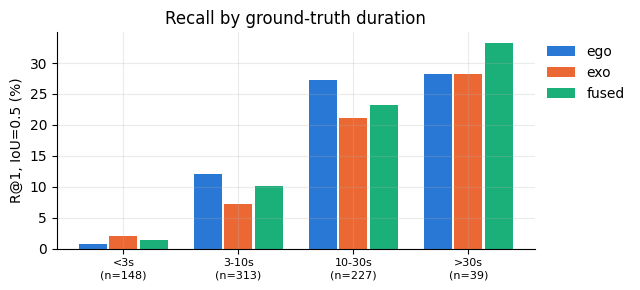

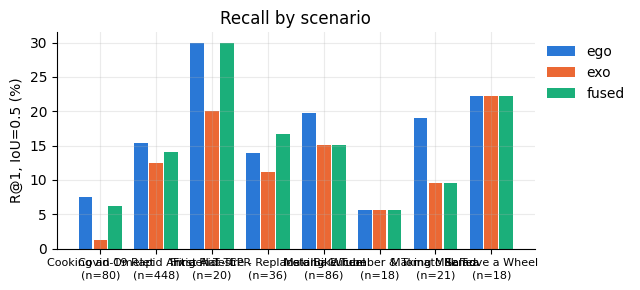

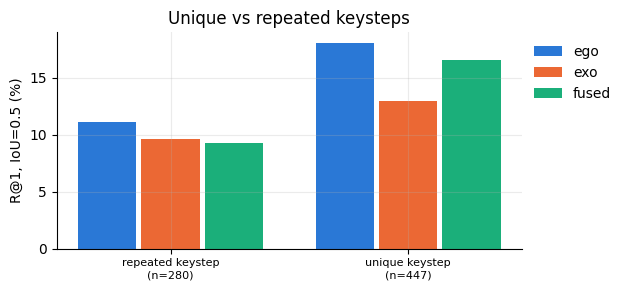

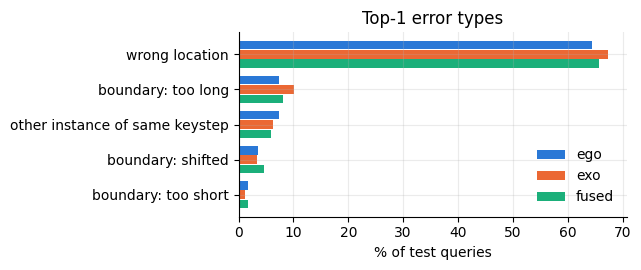

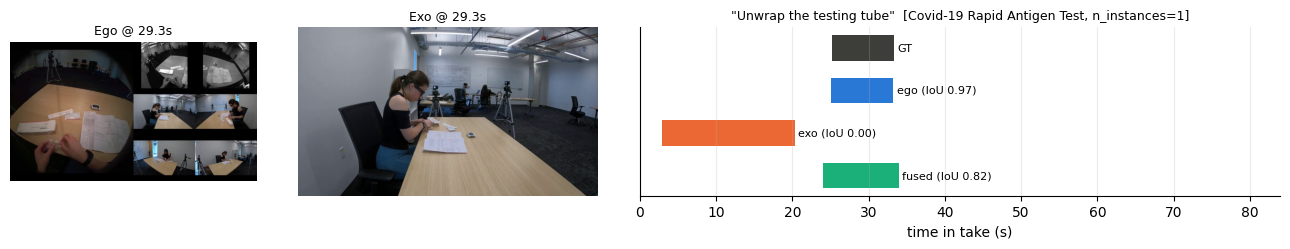

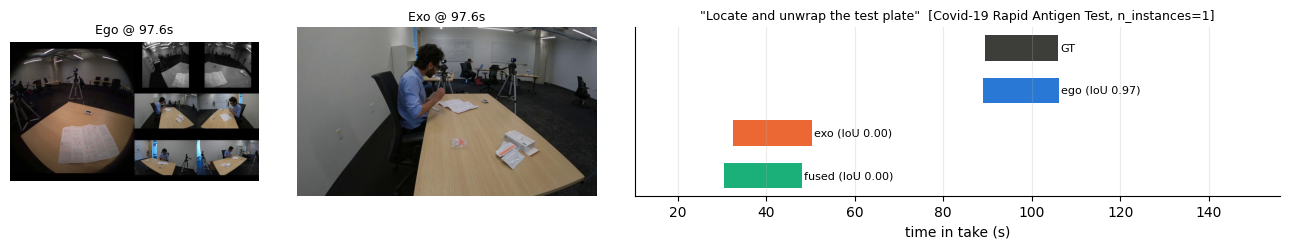

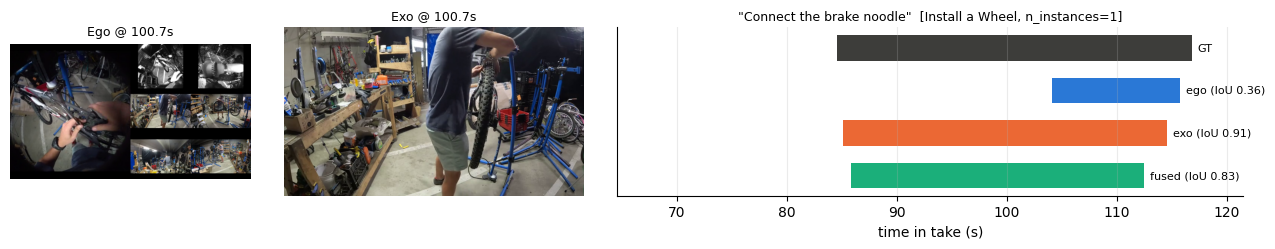

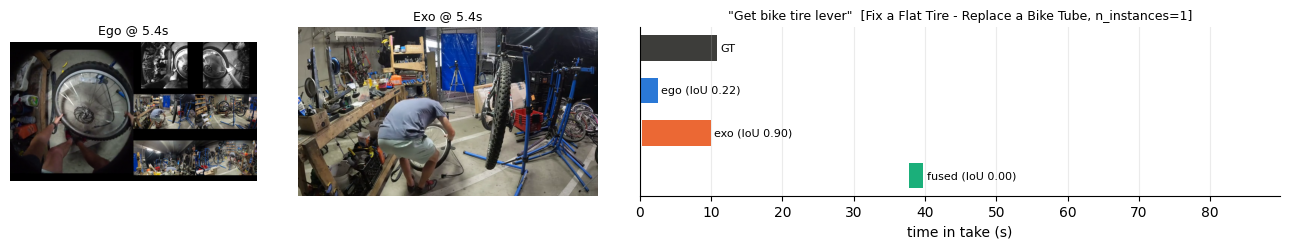

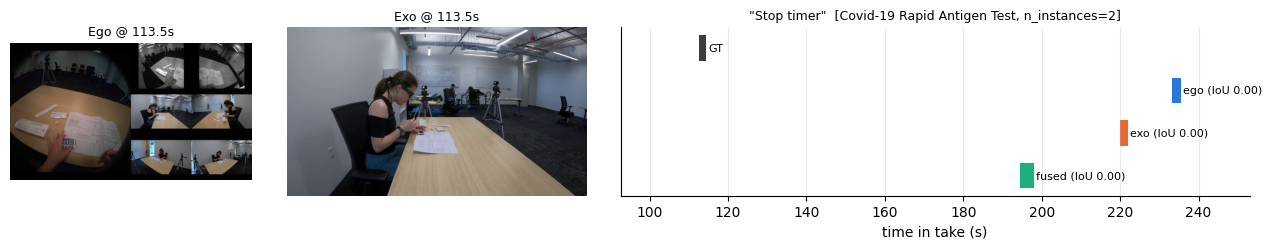

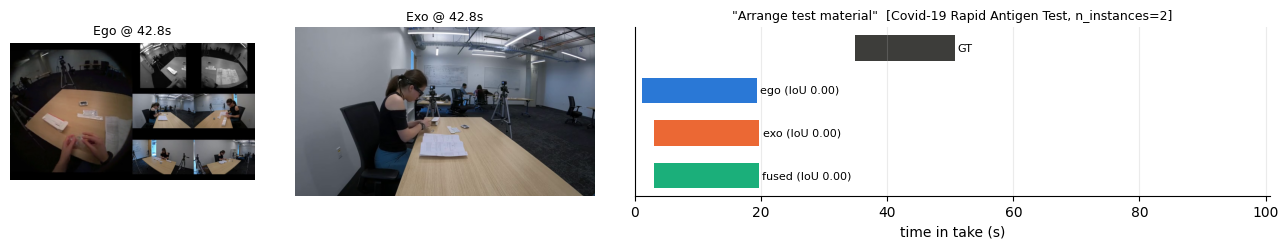

In [ ]:
COLORS = {"ego": "#2a78d6", "exo": "#eb6834", "fused": "#1baf7a", "gt": "#3d3d3a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})


def grouped_bars(table, models, title, fname):
    fig, ax = plt.subplots(figsize=(6.5, 3))
    x = np.arange(len(table))
    w = 0.8 / len(models)
    for j, m in enumerate(models):
        ax.bar(x + (j - (len(models) - 1) / 2) * w, table[f"{m} R1@0.5"], w * 0.92, color=COLORS[m], label=m)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(table.index, table["n"])], fontsize=8)
    ax.set_ylabel("R@1, IoU=0.5 (%)")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    fig.savefig(f"{fig_dir}/{fname}", dpi=200, bbox_inches="tight")
    plt.show()


grouped_bars(breakdown(A, "len_bin", models), models, "Recall by ground-truth duration", "recall_by_length.png")
grouped_bars(breakdown(A, "scenario", models), models, "Recall by scenario", "recall_by_scenario.png")
grouped_bars(breakdown(A, "repeated", models), models, "Unique vs repeated keysteps", "recall_by_repeated.png")

err_plot = err_table.drop(index="correct", errors="ignore")
fig, ax = plt.subplots(figsize=(6.5, 2.8))
y = np.arange(len(err_plot))
h = 0.8 / len(models)
for j, m in enumerate(models):
    ax.barh(y + (j - (len(models) - 1) / 2) * h, err_plot[m], h * 0.92, color=COLORS[m], label=m)
ax.set_yticks(y)
ax.set_yticklabels(err_plot.index)
ax.invert_yaxis()
ax.set_xlabel("% of test queries")
ax.set_title("Top-1 error types")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{fig_dir}/error_types.png", dpi=200, bbox_inches="tight")
plt.show()


def grab_frame(path, t):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ok, frame = cap.read()
    cap.release()
    return frame[..., ::-1] if ok else None


def show_example(row_id, fname=None, context=20):
    r = A.set_index("row_id").loc[row_id]
    mid = (r.start_sec + r.end_sec) / 2
    exo_paths = take_info.loc[r.take_uid, "exo_colab_paths"]
    exo_path = ([p for p in exo_paths if "cam01" in Path(p).stem] or exo_paths)[0]
    fig, axes = plt.subplots(1, 3, figsize=(13, 2.6), gridspec_kw={"width_ratios": [1, 1.4, 2.6]})
    for ax, path, title in [(axes[0], take_info.loc[r.take_uid, "ego_colab_path"], "Ego"), (axes[1], exo_path, "Exo")]:
        frame = grab_frame(path, mid)
        if frame is not None:
            ax.imshow(frame)
        ax.set_title(f"{title} @ {mid:.1f}s", fontsize=9)
        ax.axis("off")
    ax = axes[2]
    bars = [("GT", r.start_sec, r.end_sec, COLORS["gt"])] + \
           [(f"{m} (IoU {r[f'iou_{m}']:.2f})", r[f"ps_{m}"], r[f"pe_{m}"], COLORS[m]) for m in models]
    for i, (label, s, e, c) in enumerate(bars):
        ax.barh(len(bars) - 1 - i, e - s, left=s, height=0.6, color=c)
        ax.text(e + 0.5, len(bars) - 1 - i, label, va="center", fontsize=8)
    lo = min(b[1] for b in bars) - context
    hi = max(b[2] for b in bars) + context * 2.5
    ax.set_xlim(max(0, lo), min(r.duration, hi))
    ax.set_yticks([])
    ax.set_xlabel("time in take (s)")
    ax.set_title(f'"{r["query"]}"  [{r["scenario"]}, n_instances={r["n_instances"]}]', fontsize=9)
    fig.tight_layout()
    if fname:
        fig.savefig(f"{fig_dir}/{fname}", dpi=200, bbox_inches="tight")
    plt.show()


ego_wins = A[A.hit_ego & ~A.hit_exo].sort_values("iou_ego", ascending=False)
exo_wins = A[A.hit_exo & ~A.hit_ego].sort_values("iou_exo", ascending=False)
wrong_inst = A[A["err_fused"] == "other instance of same keystep"]
for name, sub in [("ego_wins", ego_wins), ("exo_wins", exo_wins), ("wrong_instance", wrong_inst)]:
    for k, rid in enumerate(sub["row_id"].head(2)):
        show_example(rid, f"qual_{name}_{k}.png")

In [ ]:
results_path = f"{output_dir}/results.csv"
EXPERIMENTS = [
    {"name": "ego",                      "streams": ["ego"]},
    {"name": "exo",                      "streams": ["exo"]},
    {"name": "ego+exo",                  "streams": ["ego", "exo"]},
    {"name": "ego+exo+gaze",             "streams": ["ego", "exo", "gaze"]},
    {"name": "ego+exo+pose",             "streams": ["ego", "exo", "pose"]},
    {"name": "ego+exo+pose+gaze",        "streams": ["ego", "exo", "pose", "gaze"]},
    {"name": "ego+exo (no pretraining)", "streams": ["ego", "exo"], "pretrained": False},
]
rows = []
for exp in EXPERIMENTS:
    for f in sorted(glob.glob(f"{pred_dir}/{exp_tag(exp['name'])}_seed*.csv")):
        seed = int(re.search(r"_seed(\d+)\.csv$", f).group(1))
        rows.append({"name": exp["name"], "seed": seed, **evaluate(pd.read_csv(f), test_df)})
pd.DataFrame(rows).to_csv(results_path, index=False)
print(pd.DataFrame(rows)[["name", "seed", "R1@0.5", "mIoU"]])

                        name  seed     R1@0.5       mIoU
0                        ego     0  15.405777  15.007122
1                        ego     1  13.204952  13.501046
2                        ego     2  11.966988  12.443302
3                        exo     0  11.691884  12.380728
4                    ego+exo     0  13.755158  14.019043
5                    ego+exo     1  14.993122  15.592983
6                    ego+exo     2  13.892710  14.046455
7               ego+exo+gaze     0  12.654746  12.600943
8               ego+exo+pose     0  13.204952  13.024058
9          ego+exo+pose+gaze     0  14.305365  13.460234
10         ego+exo+pose+gaze     1  12.517194  12.964655
11         ego+exo+pose+gaze     2  11.966988  12.882182
12  ego+exo (no pretraining)     0   3.713893   4.966314


In [ ]:
MAP_TIOUS = [0.3, 0.5, 0.7]


def query_ap(pred_segs, pred_scores, gt_segs, tiou):
    order = np.argsort(-np.asarray(pred_scores))
    matched = np.zeros(len(gt_segs), dtype=bool)
    tp, precisions = 0, []
    for rank, k in enumerate(order, start=1):
        ious = seg_iou(np.full(len(gt_segs), pred_segs[k][0]), np.full(len(gt_segs), pred_segs[k][1]),
                       gt_segs[:, 0], gt_segs[:, 1])
        ious[matched] = -1
        j = int(np.argmax(ious))
        if ious[j] >= tiou:
            matched[j] = True
            tp += 1
            precisions.append(tp / rank)
    return sum(precisions) / len(gt_segs)


def segment_map(preds, examples, participant_col=None):
    preds = preds.set_index("row_id")
    rows = []
    for (take, query), g in examples.groupby(["take_uid", "query"]):
        p = preds.loc[g["row_id"].iloc[0]]          # same video + same query -> same predictions
        segs, scores = [], []
        for j in range(1, 6):
            if f"pred_start_{j}" not in p.index or pd.isna(p[f"pred_start_{j}"]):
                continue
            seg = (round(p[f"pred_start_{j}"], 3), round(p[f"pred_end_{j}"], 3))
            if seg in segs:                          # top-k list is padded with repeats
                continue
            segs.append(seg)
            scores.append(p.get(f"score_{j}", 1.0 / j))
        gt = g[["start_sec", "end_sec"]].values
        ap = np.mean([query_ap(segs, scores, gt, t) for t in MAP_TIOUS])
        rows.append({"take_uid": take, "query": query, "ap": ap,
                     "participant": g[participant_col].iloc[0] if participant_col else take})
    q = pd.DataFrame(rows)
    per_take = q.groupby(["participant", "take_uid"])["ap"].mean().reset_index()
    per_participant = per_take.groupby("participant")["ap"].mean()
    return per_participant.mean() * 100, len(q)


participant_col = next((c for c in ["participant_uid", "participant_id", "participant"] if c in test_df.columns), None)
print("participant column:", participant_col)

map_rows = []
for exp in EXPERIMENTS:
    for f in sorted(glob.glob(f"{pred_dir}/{exp_tag(exp['name'])}_seed*.csv")):
        seed = int(re.search(r"_seed(\d+)\.csv$", f).group(1))
        m, n_q = segment_map(pd.read_csv(f), test_df, participant_col)
        map_rows.append({"name": exp["name"], "seed": seed, "mAP": m})
m, n_q = segment_map(prior_preds(train_df, test_df), test_df, participant_col)
map_rows.append({"name": "Keystep position prior (text only)", "seed": 0, "mAP": m})

map_df = pd.DataFrame(map_rows)
map_table = map_df.groupby("name")["mAP"].agg(["mean", "std", "count"]).round(2)
map_table = map_table.reindex([n for n in ["Keystep position prior (text only)"] + [e["name"] for e in EXPERIMENTS]
                               if n in map_table.index])
print(f"{n_q} unique (take, query) pairs; mAP averaged over tIoU {MAP_TIOUS}")
display(map_table)
map_df.to_csv(f"{output_dir}/map_results.csv", index=False)

participant column: None
555 unique (take, query) pairs; mAP averaged over tIoU [0.3, 0.5, 0.7]


,mean,std,count
name,,,
Keystep position prior (text only),11.82,NaN,1
ego,26.18,1.83,3
exo,26.10,NaN,1
ego+exo,28.15,0.36,3
ego+exo+gaze,27.83,NaN,1
ego+exo+pose,26.36,NaN,1
ego+exo+pose+gaze,27.76,1.61,3
ego+exo (no pretraining),15.84,NaN,1


In [ ]:
BASE = "ego+exo"
ADDED = ["ego+exo+pose", "ego+exo+gaze", "ego+exo+pose+gaze"]


def iou_of(name):
    p = load_preds(name).loc[test_df["row_id"]]
    return seg_iou(p["pred_start_1"].values, p["pred_end_1"].values, test_df["start_sec"], test_df["end_sec"])


def window_salience(take, s, e, stream, cols):
    x = FEATS[take][stream]
    valid = x[:, -1] > 0
    lo, hi = int(s / FEAT_STRIDE), max(int(s / FEAT_STRIDE) + 1, int(math.ceil(e / FEAT_STRIDE)))
    inside = np.zeros(len(x), dtype=bool)
    inside[lo:hi] = True
    if (inside & valid).sum() == 0 or (~inside & valid).sum() == 0:
        return np.nan
    v = x[:, cols].mean(1)
    return v[inside & valid].mean() - v[~inside & valid].mean()


Q = test_df.copy()
Q["iou_base"] = iou_of(BASE)
for name in ADDED:
    Q[f"iou_{name}"] = iou_of(name)
Q["len_bin"] = pd.cut(Q["gt_len"], [0, 3, 10, 30, 1e9], labels=["<3s", "3-10s", "10-30s", ">30s"])
Q["repeated"] = np.where(Q["n_instances"] > 1, "repeated", "unique")
Q["pose_motion"] = [window_salience(r.take_uid, r.start_sec, r.end_sec, "pose", list(range(17))) for r in Q.itertuples()]
Q["wrist_motion"] = [window_salience(r.take_uid, r.start_sec, r.end_sec, "pose", [9, 10]) for r in Q.itertuples()]
Q["leg_motion"] = [window_salience(r.take_uid, r.start_sec, r.end_sec, "pose", [13, 14, 15, 16]) for r in Q.itertuples()]
Q["gaze_velocity"] = [window_salience(r.take_uid, r.start_sec, r.end_sec, "gaze", [4]) for r in Q.itertuples()]
Q["gaze_spread"] = [window_salience(r.take_uid, r.start_sec, r.end_sec, "gaze", [2, 3]) for r in Q.itertuples()]
Q["gaze_source"] = Q["take_uid"].map(
    lambda t: "personalized" if "personalized" in str(take_info.loc[t, "gaze_path"]) else "general")

rows = []
for name in ADDED:
    hb, hn = Q["iou_base"] >= 0.5, Q[f"iou_{name}"] >= 0.5
    rows.append({"added": name.replace(BASE, "").lstrip("+") or name, "newly correct": int((~hb & hn).sum()),
                 "newly wrong": int((hb & ~hn).sum()), "net": int((~hb & hn).sum() - (hb & ~hn).sum()),
                 "mean dIoU (x100)": round(100 * (Q[f"iou_{name}"] - Q["iou_base"]).mean(), 2)})
print(f"=== Query-level changes vs {BASE} ===")
display(pd.DataFrame(rows).set_index("added"))


def gain_by(col, name, q=None):
    d = (Q if q is None else q).copy()
    d["dIoU x100"] = 100 * (d[f"iou_{name}"] - d["iou_base"])
    d["dR1@0.5"] = 100 * ((d[f"iou_{name}"] >= .5).astype(float) - (d["iou_base"] >= .5).astype(float))
    g = d.groupby(col, observed=True)
    out = g[["dIoU x100", "dR1@0.5"]].mean()
    out.insert(0, "n", g.size())
    return out.round(1)


for col, label in [("pose_motion", "body motion inside GT (vs rest of take)"),
                   ("wrist_motion", "wrist motion inside GT"), ("leg_motion", "leg motion inside GT")]:
    Q[col + "_bin"] = pd.qcut(Q[col], 3, labels=["low", "mid", "high"], duplicates="drop")
    print(f"\n=== +pose gain by {label} ===")
    display(gain_by(col + "_bin", "ego+exo+pose"))

for col, label in [("gaze_velocity", "gaze velocity inside GT"), ("gaze_spread", "gaze spread inside GT")]:
    Q[col + "_bin"] = pd.qcut(Q[col], 3, labels=["low", "mid", "high"], duplicates="drop")
    print(f"\n=== +gaze gain by {label} ===")
    display(gain_by(col + "_bin", "ego+exo+gaze"))

print("\n=== +gaze gain by gaze calibration ===")
display(gain_by("gaze_source", "ego+exo+gaze"))
for col in ["len_bin", "repeated", "scenario"]:
    print(f"\n=== gains by {col} (dIoU x100) ===")
    display(pd.concat({n.replace(BASE + "+", "+"): gain_by(col, n)["dIoU x100"] for n in ADDED}, axis=1)
            .assign(n=Q.groupby(col, observed=True).size()))

for name in ["ego+exo+pose", "ego+exo+gaze"]:
    k = Q.assign(d=Q[f"iou_{name}"] - Q["iou_base"]).groupby("query").agg(n=("d", "size"), dIoU=("d", "mean"))
    k = k[k["n"] >= 3]
    print(f"\n=== Keysteps most helped by {name.replace(BASE + '+', '+')} ===")
    display(k.sort_values("dIoU", ascending=False).head(8).round(3))
    print(f"=== Keysteps most hurt by {name.replace(BASE + '+', '+')} ===")
    display(k.sort_values("dIoU").head(8).round(3))

print("\n=== Spearman correlation: signal salience vs IoU gain ===")
corr = []
for name, sigs in [("ego+exo+pose", ["pose_motion", "wrist_motion", "leg_motion"]),
                   ("ego+exo+gaze", ["gaze_velocity", "gaze_spread"])]:
    d = Q[f"iou_{name}"] - Q["iou_base"]
    for s in sigs:
        ok = Q[s].notna()
        corr.append({"model": name, "signal": s, "spearman r": round(Q.loc[ok, s].rank().corr(d[ok].rank()), 3),
                     "n": int(ok.sum())})
display(pd.DataFrame(corr))
Q.to_csv(f"{output_dir}/pose_gaze_query_analysis.csv", index=False)

=== Query-level changes vs ego+exo ===


,newly correct,newly wrong,net,mean dIoU (x100)
added,,,,
pose,49,53,-4,-0.99
gaze,43,51,-8,-1.42
pose+gaze,48,44,4,-0.56



=== +pose gain by body motion inside GT (vs rest of take) ===


,n,dIoU x100,dR1@0.5
pose_motion_bin,,,
low,237,-0.2,-0.8
mid,236,-3.0,-3.0
high,237,0.5,3.0



=== +pose gain by wrist motion inside GT ===


,n,dIoU x100,dR1@0.5
wrist_motion_bin,,,
low,237,-1.5,-2.1
mid,236,-1.6,-3.4
high,237,0.4,4.6


... (20 outputs left out)

=== Keysteps most hurt by +gaze ===


,n,dIoU
query,,
Wait for 15 minutes,8,-0.313
Turn on the stove,3,-0.267
Pull the release lever outwards,3,-0.266
Squeeze out any air inside the tube,4,-0.249
Check the expiration date,3,-0.217
Get a timer,3,-0.199
Roll the wheel,12,-0.176
Rotate the pedal,4,-0.174



=== Spearman correlation: signal salience vs IoU gain ===


,model,signal,spearman r,n
0,ego+exo+pose,pose_motion,0.024,710
1,ego+exo+pose,wrist_motion,0.027,710
2,ego+exo+pose,leg_motion,-0.023,710
3,ego+exo+gaze,gaze_velocity,0.012,727
4,ego+exo+gaze,gaze_spread,0.009,727


In [ ]:
SEEDS3 = [0, 1, 2]
BASE, FULL = "ego+exo", "ego+exo+pose+gaze"


def iou_seed(name, seed):
    p = load_preds(name, seed).loc[test_df["row_id"]]
    return seg_iou(p["pred_start_1"].values, p["pred_end_1"].values, test_df["start_sec"], test_df["end_sec"])


IOU = {(m, s): iou_seed(m, s) for m in [BASE, FULL] for s in SEEDS3}

def spearman(a, b):
    return pd.Series(a).rank().corr(pd.Series(b).rank())

d = {s: IOU[(FULL, s)] - IOU[(BASE, s)] for s in SEEDS3}
rows = [{"comparison": f"pose+gaze gain, seed {a} vs seed {b}", "spearman r": spearman(d[a], d[b])}
        for a, b in [(0, 1), (0, 2), (1, 2)]]
print("=== (1) Cross-seed consistency of per-query pose+gaze gains ===")
display(pd.DataFrame(rows).round(3))

real_r = np.mean([spearman(d[a], d[b]) for a, b in [(0, 1), (0, 2), (1, 2)]])
rng = np.random.RandomState(0)
perm = [np.mean([spearman(rng.permutation(d[a]), d[b]) for a, b in [(0, 1), (0, 2), (1, 2)]]) for _ in range(200)]
print(f"mean cross-seed r = {real_r:.3f}; permutation p = {np.mean(np.array(perm) >= real_r):.3f}")

helped = np.all([d[s] > 0.1 for s in SEEDS3], axis=0)
hurt = np.all([d[s] < -0.1 for s in SEEDS3], axis=0)
print(f"helped in all 3 seeds (dIoU > 0.1): {helped.sum()} | hurt in all 3 seeds: {hurt.sum()}")
cons = test_df.assign(consistent=np.where(helped, "helped x3", np.where(hurt, "hurt x3", "mixed")))
display(cons[cons.consistent != "mixed"].groupby(["consistent", "scenario"]).size().unstack(0).fillna(0).astype(int))
display(cons[cons.consistent == "helped x3"][["scenario", "query", "start_sec", "end_sec", "gt_len"]].head(15))

def oracle(a, b):
    return 100 * (np.maximum(a, b) >= 0.5).mean()

rows = []
for s in SEEDS3:
    rows.append({"seed": s, "base R1@0.5": 100 * (IOU[(BASE, s)] >= .5).mean(),
                 "oracle(base, pose+gaze)": oracle(IOU[(BASE, s)], IOU[(FULL, s)]),
                 "oracle(base, base re-run)": oracle(IOU[(BASE, s)], IOU[(BASE, (s + 1) % 3)])})
print("\n=== (2) Oracle modality selection vs re-run noise (R1@0.5) ===")
display(pd.DataFrame(rows).round(1).set_index("seed"))


def boundary_auc(stream, cols, window=1.0):
    pos, neg = [], []
    rng = np.random.RandomState(0)
    for r in test_df.itertuples():
        x = FEATS[r.take_uid][stream]
        v = np.abs(np.diff(x[:, cols].mean(1), prepend=x[0, cols].mean())) * (x[:, -1] > 0)
        T, w = len(v), int(window / FEAT_STRIDE)
        for b in [r.start_sec, r.end_sec]:
            i = int(b / FEAT_STRIDE)
            if w <= i < T - w:
                pos.append(v[i - w:i + w + 1].mean())
                j = rng.randint(w, T - w)
                neg.append(v[j - w:j + w + 1].mean())
    pos, neg = np.array(pos), np.array(neg)
    return (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean(), len(pos)

rows = []
for name, stream, cols in [("pose: all joints", "pose", list(range(17))), ("pose: wrists", "pose", [9, 10]),
                           ("pose: legs", "pose", [13, 14, 15, 16]), ("gaze: velocity", "gaze", [4]),
                           ("gaze: spread", "gaze", [2, 3]),
                           ("ego video (CLIP change)", "ego", list(range(512))),
                           ("exo video (CLIP change)", "exo", list(range(512)))]:
    if stream in ["ego", "exo"]:
        pos, neg = [], []
        rng = np.random.RandomState(0)
        for r in test_df.itertuples():
            x = FEATS[r.take_uid][stream].astype(np.float32)
            v = np.r_[0, np.linalg.norm(np.diff(x, axis=0), axis=1)]
            T, w = len(v), int(1.0 / FEAT_STRIDE)
            for b in [r.start_sec, r.end_sec]:
                i = int(b / FEAT_STRIDE)
                if w <= i < T - w:
                    pos.append(v[i - w:i + w + 1].mean())
                    j = rng.randint(w, T - w)
                    neg.append(v[j - w:j + w + 1].mean())
        pos, neg = np.array(pos), np.array(neg)
        auc, n = (pos[:, None] > neg[None, :]).mean(), len(pos)
    else:
        auc, n = boundary_auc(stream, cols)
    rows.append({"signal": name, "boundary AUC": round(auc, 3), "n boundaries": n})
print("\n=== (3) Do raw signals change more at keystep boundaries than at random times? (0.5 = no) ===")
display(pd.DataFrame(rows))

=== (1) Cross-seed consistency of per-query pose+gaze gains ===


,comparison,spearman r
0,"pose+gaze gain, seed 0 vs seed 1",0.178
1,"pose+gaze gain, seed 0 vs seed 2",0.273
2,"pose+gaze gain, seed 1 vs seed 2",0.137


mean cross-seed r = 0.196; permutation p = 0.000
helped in all 3 seeds (dIoU > 0.1): 15 | hurt in all 3 seeds: 29


consistent,helped x3,hurt x3
scenario,,
Cooking an Omelet,0,2
Covid-19 Rapid Antigen Test,10,13
First Aid - CPR,0,1
Fix a Flat Tire - Replace a Bike Tube,1,1
Install a Wheel,2,8
Making Cucumber & Tomato Salad,0,1
Remove a Wheel,2,3


,scenario,query,start_sec,end_sec,gt_len
10,Covid-19 Rapid Antigen Test,Apply a few drops of the testing solution to t...,150.39070,166.39248,16.00178
54,Covid-19 Rapid Antigen Test,cover the test tube,214.05825,219.74510,5.68685
58,Covid-19 Rapid Antigen Test,Apply a few drops of the testing solution to t...,235.62013,242.01159,6.39146
141,Covid-19 Rapid Antigen Test,Slowly extract the swab from the nostril,203.95413,205.42300,1.46887
144,Covid-19 Rapid Antigen Test,Apply a few drops of the testing solution to t...,252.21453,276.08870,23.87417
147,Covid-19 Rapid Antigen Test,Wait for 15 minutes,290.28727,301.50000,11.21273
170,Covid-19 Rapid Antigen Test,Read the instructions,7.48347,17.98524,10.50177
197,Covid-19 Rapid Antigen Test,Read the instructions,22.86000,27.94216,5.08216
230,Covid-19 Rapid Antigen Test,Unwrap testing plate,64.70770,80.72173,16.01403
321,Covid-19 Rapid Antigen Test,Locate and unwrap the collection swab,24.79546,28.26160,3.46614



=== (2) Oracle modality selection vs re-run noise (R1@0.5) ===


,base R1@0.5,"oracle(base, pose+gaze)","oracle(base, base re-run)"
seed,,,
0,13.8,20.4,19.4
1,15.0,20.6,20.5
2,13.9,19.1,18.2



=== (3) Do raw signals change more at keystep boundaries than at random times? (0.5 = no) ===


,signal,boundary AUC,n boundaries
0,pose: all joints,0.621,1418
1,pose: wrists,0.624,1418
2,pose: legs,0.552,1418
3,gaze: velocity,0.623,1418
4,gaze: spread,0.620,1418
5,ego video (CLIP change),0.631,1418
6,exo video (CLIP change),0.643,1418


In [ ]:
fail_mask = iou_seed("ego+exo", 0) < 0.5

def subset_auc(sub, stream, cols, window=1.0):
    pos, neg = [], []
    rng = np.random.RandomState(0)
    for r in sub.itertuples():
        x = FEATS[r.take_uid][stream].astype(np.float32)
        if stream in ["ego", "exo"]:
            v = np.r_[0, np.linalg.norm(np.diff(x, axis=0), axis=1)]
        else:
            v = np.abs(np.diff(x[:, cols].mean(1), prepend=x[0, cols].mean())) * (x[:, -1] > 0)
        T, w = len(v), int(window / FEAT_STRIDE)
        for b in [r.start_sec, r.end_sec]:
            i = int(b / FEAT_STRIDE)
            if w <= i < T - w:
                pos.append(v[i - w:i + w + 1].mean())
                j = rng.randint(w, T - w)
                neg.append(v[j - w:j + w + 1].mean())
    pos, neg = np.array(pos), np.array(neg)
    return round(float((pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()), 3)

subsets = {"ego+exo correct": test_df[~fail_mask], "ego+exo wrong": test_df[fail_mask],
           "short (<3s) & wrong": test_df[fail_mask & (test_df["gt_len"] < 3)],
           "repeated & wrong": test_df[fail_mask & (test_df["n_instances"] > 1)]}
signals = [("pose", "pose", list(range(17))), ("wrists", "pose", [9, 10]), ("gaze vel.", "gaze", [4]),
           ("ego video", "ego", None), ("exo video", "exo", None)]
display(pd.DataFrame({name: {sig: subset_auc(sub, st, c) for sig, st, c in signals} for name, sub in subsets.items()}).T
        .assign(n=[len(s) for s in subsets.values()]))

,pose,wrists,gaze vel.,ego video,exo video,n
ego+exo correct,0.613,0.655,0.624,0.640,0.704,100
ego+exo wrong,0.616,0.626,0.613,0.621,0.628,627
short (<3s) & wrong,0.595,0.613,0.610,0.592,0.604,146
repeated & wrong,0.596,0.605,0.610,0.617,0.613,254


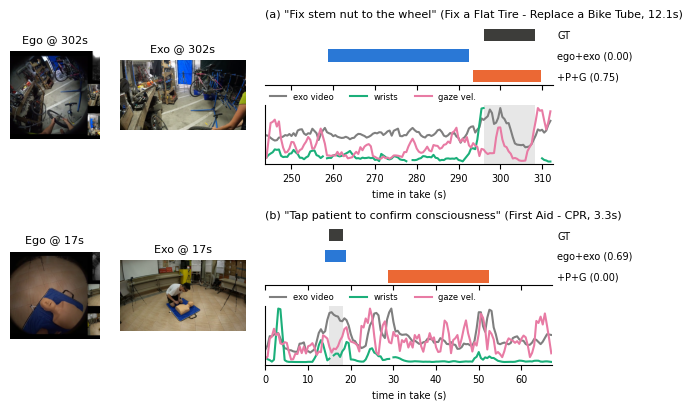

helped example: Fix stem nut to the wheel | hurt example: Tap patient to confirm consciousness
Other candidates (helped in all 3 seeds): ['Apply a few drops of the testing solution to the testing plate', 'cover the test tube', 'Apply a few drops of the testing solution to the testing plate', 'Slowly extract the swab from the nostril', 'Apply a few drops of the testing solution to the testing plate', 'Wait for 15 minutes', 'Read the instructions', 'Read the instructions', 'Unwrap testing plate', 'Locate and unwrap the collection swab', 'Fix stem nut to the wheel', 'Pivot the derailleur back', 'Pivot the derailleur back', 'Put the bike upside down', 'Put the wheel fully seated into the fork']
Other candidates (hurt in all 3 seeds): ['Unbox package', 'Wait for 15 minutes', 'Wait for 15 minutes', 'Unbox package', 'Apply a few drops of the testing solution to the testing plate', 'Arrange test material', 'Apply a few drops of the testing solution to the testing plate', 'Apply a few drops of 

In [ ]:
import cv2
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec
plt.rcParams["axes.grid"] = False
C = {"gt": "#3d3d3a", "ego+exo": "#2a78d6", "ego+exo+pose+gaze": "#eb6834",
     "exo video": "#7f7f7f", "wrists": "#1baf7a", "gaze vel.": "#e87ba4"}


def grab_frame(path, t):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ok, frame = cap.read()
    cap.release()
    if ok and "preview" in path:
        frame = frame[:, : int(frame.shape[1] * 0.58)]
    return frame[..., ::-1] if ok else None


def signal_change(take, stream, cols):
    x = FEATS[take][stream].astype(np.float32)
    if stream in ["ego", "exo"]:
        return np.r_[0, np.linalg.norm(np.diff(x, axis=0), axis=1)]
    v = np.abs(np.diff(x[:, cols].mean(1), prepend=x[0, cols].mean()))
    return np.where(x[:, -1] > 0, v, np.nan)


def pick(kind):
    sub = cons[cons.consistent == kind].copy()
    sub["mean_d"] = np.mean([IOU[(FULL, s)][sub.index] - IOU[(BASE, s)][sub.index] for s in SEEDS3], axis=0)
    return sub.sort_values("mean_d", ascending=(kind == "hurt x3")).iloc[0]


def draw_example(fig, spec, r, label, context=15):
    rid = r["row_id"]
    gs = GridSpecFromSubplotSpec(2, 3, subplot_spec=spec, width_ratios=[1, 1.4, 3.2], height_ratios=[1, 1],
                                 wspace=0.12, hspace=0.35)
    mid = (r["start_sec"] + r["end_sec"]) / 2
    exo_paths = take_info.loc[r["take_uid"], "exo_colab_paths"]
    exo_path = ([p for p in exo_paths if "cam01" in Path(p).stem] or exo_paths)[0]
    for k, (path, name) in enumerate([(take_info.loc[r["take_uid"], "ego_colab_path"], "Ego"), (exo_path, "Exo")]):
        ax = fig.add_subplot(gs[:, k])
        frame = grab_frame(path, mid)
        if frame is not None:
            ax.imshow(frame)
        ax.set_title(f"{name} @ {mid:.0f}s", fontsize=8)
        ax.axis("off")

    bars = [("GT", r["start_sec"], r["end_sec"], C["gt"])]
    for m, short in [(BASE, "ego+exo"), (FULL, "+P+G")]:
        p = load_preds(m, 0).loc[rid]
        iou = seg_iou(p["pred_start_1"], p["pred_end_1"], r["start_sec"], r["end_sec"])
        bars.append((f"{short} ({float(iou):.2f})", p["pred_start_1"], p["pred_end_1"], C[m]))
    lo = max(0, min(b[1] for b in bars) - context)
    hi = min(r["duration"], max(b[2] for b in bars) + context)
    ax = fig.add_subplot(gs[0, 2])
    for i, (lab, s_, e_, c) in enumerate(bars):
        ax.barh(len(bars) - 1 - i, e_ - s_, left=s_, height=0.6, color=c)
    ax.set_yticks(range(len(bars)))
    ax.set_yticklabels([b[0] for b in bars][::-1], fontsize=6.5)
    ax.tick_params(axis="y", length=0)
    ax.yaxis.tick_right()
    ax.set_xlim(lo, hi)
    ax.tick_params(labelbottom=False, labelsize=7)
    ax.set_title(f'{label} "{r["query"]}" ({r["scenario"]}, {r["gt_len"]:.1f}s)', fontsize=8, loc="left")
    for side in ["top", "left"]:
        ax.spines[side].set_visible(False)

    ax = fig.add_subplot(gs[1, 2])
    t = np.arange(len(FEATS[r["take_uid"]]["ego"])) * FEAT_STRIDE
    win = (t >= lo) & (t <= hi)
    for name, stream, cols in [("exo video", "exo", None), ("wrists", "pose", [9, 10]), ("gaze vel.", "gaze", [4])]:
        v = pd.Series(signal_change(r["take_uid"], stream, cols)[win]).rolling(3, center=True, min_periods=1).mean()
        ax.plot(t[win], v / np.nanmax(v) if np.nanmax(v) > 0 else v, color=C[name], lw=1.5, label=name)
    ax.axvspan(r["start_sec"], r["end_sec"], color=C["gt"], alpha=0.12, lw=0)
    ax.set_xlim(lo, hi)
    ax.set_yticks([])
    ax.tick_params(labelsize=7)
    ax.set_xlabel("time in take (s)", fontsize=7)
    ax.legend(fontsize=6, frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.1)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)


ex_help, ex_hurt = pick("helped x3"), pick("hurt x3")
fig = plt.figure(figsize=(7, 4.4))
outer = fig.add_gridspec(2, 1, hspace=0.45)
draw_example(fig, outer[0], ex_help, "(a)")
draw_example(fig, outer[1], ex_hurt, "(b)")
fig.savefig(f"{fig_dir}/qualitative_pose_gaze.png", dpi=250, bbox_inches="tight")
fig.savefig(f"{fig_dir}/qualitative_pose_gaze.pdf", bbox_inches="tight")
plt.show()
print("helped example:", ex_help["query"], "| hurt example:", ex_hurt["query"])
print("Other candidates (helped in all 3 seeds):", cons[cons.consistent == "helped x3"]["query"].tolist())
print("Other candidates (hurt in all 3 seeds):", cons[cons.consistent == "hurt x3"]["query"].tolist())

In [ ]:
EXPERIMENTS_SEEDS = [
    {"name": "ego",               "streams": ["ego"]},
    {"name": "ego+exo",           "streams": ["ego", "exo"]},
    {"name": "ego+exo+pose+gaze", "streams": ["ego", "exo", "pose", "gaze"]},
]
SEEDS = [0, 1, 2]

results_path = f"{output_dir}/results.csv"
results = pd.read_csv(results_path).to_dict("records") if os.path.exists(results_path) else []
done = {(r["name"], r["seed"]) for r in results}

for exp in EXPERIMENTS_SEEDS:
    for seed in SEEDS:
        if (exp["name"], seed) in done or os.path.exists(f"{pred_dir}/{exp_tag(exp['name'])}_seed{seed}.csv"):
            continue
        t0 = time.time()
        model, cfg, data, hist = train_groundnlq(exp, seed=seed)
        preds = predict_groundnlq(model, make_eval_dataset(cfg, data["test"]), test_df)
        tag = exp_tag(exp["name"])
        preds.to_csv(f"{pred_dir}/{tag}_seed{seed}.csv", index=False)
        hist.to_csv(f"{output_dir}/history_{tag}_seed{seed}.csv", index=False)
        res = {"name": exp["name"], "seed": seed, **evaluate(preds, test_df), "minutes": (time.time() - t0) / 60}
        print(res)
        results.append(res)
        pd.DataFrame(results).to_csv(results_path, index=False)
        del model
        torch.cuda.empty_cache()
print("All seed runs done")

loaded 466/467 tensors | re-initialized: ['backbone.vid_embd.0.conv.weight']
len of dataset:  1743
len of dataset:  276

[Train]: [GPU0] Epoch 0 started


training one epoch: 435it [07:19,  1.01s/it]


[Train]: [GPU0] Epoch 0 finished with lr=0.00005000

[ego] epoch 0 model val R1@0.3 14.1 R1@0.5 9.1 mIoU 9.9
[ego] epoch 0 ema   val R1@0.3 8.0 R1@0.5 1.8 mIoU 7.2

[Train]: [GPU0] Epoch 1 started


training one epoch: 435it [07:20,  1.01s/it]


[Train]: [GPU0] Epoch 1 finished with lr=0.00003750

[ego] epoch 1 model val R1@0.3 21.0 R1@0.5 13.8 mIoU 13.9
[ego] epoch 1 ema   val R1@0.3 12.0 R1@0.5 5.1 mIoU 8.8

[Train]: [GPU0] Epoch 2 started


training one epoch: 435it [07:21,  1.01s/it]


... (39 outputs left out)

training one epoch: 435it [07:29,  1.03s/it]


[Train]: [GPU0] Epoch 2 finished with lr=0.00001251

[ego+exo+pose+gaze] epoch 2 model val R1@0.3 22.5 R1@0.5 15.6 mIoU 16.4
[ego+exo+pose+gaze] epoch 2 ema   val R1@0.3 15.6 R1@0.5 11.2 mIoU 11.6

[Train]: [GPU0] Epoch 3 started


training one epoch: 435it [07:27,  1.03s/it]


[Train]: [GPU0] Epoch 3 finished with lr=0.00000001

[ego+exo+pose+gaze] epoch 3 model val R1@0.3 23.2 R1@0.5 17.8 mIoU 17.0
[ego+exo+pose+gaze] epoch 3 ema   val R1@0.3 18.8 R1@0.5 13.0 mIoU 13.4
len of dataset:  727
{'name': 'ego+exo+pose+gaze', 'seed': 2, 'R1@0.3': np.float64(18.56946354883081), 'R1@0.5': np.float64(11.966987620357635), 'R1@0.7': np.float64(6.464924346629987), 'R5@0.3': np.float64(48.143053645116915), 'R5@0.5': np.float64(34.25034387895461), 'mIoU': np.float64(12.882182181929574), 'R1@0.5 any-inst': np.float64(16.506189821182943), 'n': 727, 'minutes': 33.189241123199466}
All seed runs done


In [ ]:
def hits(name, seed):
    p = load_preds(name, seed).loc[test_df["row_id"]]
    return seg_iou(p["pred_start_1"].values, p["pred_end_1"].values, test_df["start_sec"], test_df["end_sec"]) >= 0.5

for a, b in [(("ego+exo", 0), ("ego+exo", 1)), (("ego+exo", 0), ("ego+exo", 2)), (("ego+exo", 1), ("ego+exo", 2)),
             (("ego+exo", 0), ("ego+exo+pose+gaze", 0))]:
    ha, hb = hits(*a), hits(*b)
    print(f"{a} vs {b}: newly correct {int((~ha & hb).sum())}, newly wrong {int((ha & ~hb).sum())}")

('ego+exo', 0) vs ('ego+exo', 1): newly correct 41, newly wrong 32
('ego+exo', 0) vs ('ego+exo', 2): newly correct 32, newly wrong 31
('ego+exo', 1) vs ('ego+exo', 2): newly correct 40, newly wrong 48
('ego+exo', 0) vs ('ego+exo+pose+gaze', 0): newly correct 48, newly wrong 44


In [ ]:
def iou_seed(name, seed):
    p = load_preds(name, seed).loc[test_df["row_id"]]
    return seg_iou(p["pred_start_1"].values, p["pred_end_1"].values, test_df["start_sec"], test_df["end_sec"])

rows = []
pairs = [("ego", s, "ego", t) for s, t in [(0, 1), (0, 2), (1, 2)]]                           # noise reference
pairs += [("ego", s, m, s) for m in ["ego+exo", "ego+exo+pose+gaze"] for s in [0, 1, 2]]       # same seed
pairs += [("ego", 0, m, 0) for m in ["exo", "ego+exo+pose", "ego+exo+gaze"]]                   # seed 0 only
for a, sa, b, sb in pairs:
    if not (os.path.exists(f"{pred_dir}/{exp_tag(a)}_seed{sa}.csv") and os.path.exists(f"{pred_dir}/{exp_tag(b)}_seed{sb}.csv")):
        continue
    ia, ib = iou_seed(a, sa), iou_seed(b, sb)
    rec, reg = (ia < 0.5) & (ib >= 0.5), (ia >= 0.5) & (ib < 0.5)
    rows.append({"base": f"{a} s{sa}", "model": f"{b} s{sb}", "recovered": int(rec.sum()), "regressed": int(reg.sum()),
                 "net": int(rec.sum() - reg.sum()), "mean dIoU x100": round(100 * float(np.mean(ib - ia)), 2)})
display(pd.DataFrame(rows))

,base,model,recovered,regressed,net,mean dIoU x100
0,ego s0,ego s1,38,54,-16,-1.51
1,ego s0,ego s2,31,56,-25,-2.56
2,ego s1,ego s2,36,45,-9,-1.06
3,ego s0,ego+exo s0,40,52,-12,-0.99
4,ego s1,ego+exo s1,52,39,13,2.09
5,ego s2,ego+exo s2,39,25,14,1.60
6,ego s0,ego+exo+pose+gaze s0,52,60,-8,-1.55
7,ego s1,ego+exo+pose+gaze s1,38,43,-5,-0.54
8,ego s2,ego+exo+pose+gaze s2,42,42,0,0.44
9,ego s0,exo s0,37,64,-27,-2.63
